# <center>📊 Лекция 2. Данные — топливо ИИ, математический минимум и среда Python</center>
## <center>AI的燃料：数据、数学基础与Python环境</center>

### <center>Прикладные технологии искусственного интеллекта</center>
#### <center>Модуль 1 — Основы ИИ и подготовка инструментальной среды · 2 академических часа (90 минут)</center>

<div style='background-color: #E8F5E9; padding: 15px; border-left: 5px solid #2E7D32; margin: 20px 0;'>
<b>🎯 Цели лекции:</b><br>
1. объяснять, почему для ИИ «всё — числа», и превращать в числа текст, картинку и звук;<br>2. выполнять операции с векторами и матрицами и понимать, зачем они модели;<br>3. считать расстояние между объектами и объяснять, почему «близко = похоже»;<br>4. читать гистограммы: среднее, медиана, разброс; считать простые вероятности и применять теорему Байеса;<br>5. различать корреляцию и причинность;<br>6. называть библиотеки экосистемы Python для ИИ и уверенно работать в Jupyter.
</div>

<div style='background-color: #FFF3E0; padding: 12px; border-left: 5px solid #FB8C00; margin: 20px 0;'>
<b>⏱️ План работы (90 минут):</b><br>
• Данные: виды, источники, почему «данные — новое масло» <i>(10 мин)</i><br>• Как компьютер «видит» мир: всё становится числами <i>(10 мин)</i><br>• Математический минимум: вектор, матрица, расстояние <i>(20 мин)</i><br>• Вероятность и статистика: среднее, разброс, Байес, корреляция <i>(25 мин)</i><br>• Python и экосистема библиотек <i>(10 мин)</i><br>• Среда: Anaconda, Jupyter, правило порядка ячеек <i>(15 мин)</i><br>• Мини-тест и итоги <i>(5 мин)</i>
</div>

<div style='background-color: #E3F2FD; padding: 12px; border-left: 5px solid #1976D2; margin: 20px 0;'>
<b>📦 Что понадобится:</b> NumPy, Pandas, Matplotlib, Jupyter Notebook.
</div>

<div style='background-color: #FCE4EC; padding: 12px; border-left: 5px solid #C2185B; margin: 20px 0;'>
<b>💡 Как работать с ноутбуком.</b> Теория читается сверху вниз; все рисунки уже внедрены в файл — внешние контейнеры и сетка не нужны. Демонстрационные ячейки с кодом можно запускать по порядку.
</div>


In [ ]:
# Настройка ноутбука: графики внутри документа, кириллица и иероглифы
%matplotlib inline
import numpy as np
import matplotlib.font_manager as fm
import os
for fp in ['/usr/share/fonts/truetype/chinese/NotoSansSC-Regular.ttf']:
    if os.path.exists(fp):
        fm.fontManager.addfont(fp)
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['Noto Sans SC', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
print('Настройка завершена. Запускайте ячейки по порядку — сверху вниз.')

Настройка завершена. Запускайте ячейки по порядку — сверху вниз.


## 1. Данные — топливо ИИ

Модель без данных — как двигатель без топлива: конструкция может быть идеальной, но движения не будет. Качество и количество данных определяют потолок системы сильнее, чем хитрость алгоритма. В индустрии говорят: **«garbage in — garbage out»** (мусор на входе — мусор на выходе, 垃圾进垃圾出).

### 1.1. Какими бывают данные

| Вид | Пример | Где берут |
|---|---|---|
| **Структурированные** | таблица студентов: рост, вес, баллы | базы данных, CRM, анкеты |
| **Неструктурированные** | фото, видео, текст писем, звук | телефон, камеры, соцсети |
| **Временные ряды** | цена акций по дням, температура | биржи, датчики, логи |
| **Графовые** | друзья в WeChat, дороги города | соцсети, карты |

80% данных мира — неструктурированные (фото, видео, текст). Именно поэтому центральные алгоритмы курса учат машины работать с ними.

### 1.2. Три свойства «хороших» данных

1. **Достаточно много.** Правило большого пальца: не меньше 10–100 примеров на признак для классических методов; глубокому обучению нужны тысячи.
2. **Разнообразны.** Если учим распознавание лиц только на фото при дневном свете — ночью система обманется. Разнообразие важнее объёма.
3. **Чисты и честны.** Ошибки в метках («спам» на нормальном письме) — яд для модели. Проверка и очистка данных — 60–80% времени дата-сайентиста (проверим на практике № 2).



### 1.3. Сколько данных нужно? «Зависит от задачи»

Единого ответа нет — масштаб растёт вместе со сложностью задачи:

| Задача | Достаточно данных |
|---|---|
| отличить два сорта цветов по 4 измерениям | ~сотня примеров |
| отличать кошку от собаки на любых фотографиях | десятки тысяч |
| обучить большую языковую модель | триллионы слов |

**Стратегия курса:** начинаем с маленьких понятных наборов (ирисы Фишера, рукописные цифры MNIST) и постепенно доходим до приёмов работы с большими объёмами. Маленькие данные — лучший тренажёр: на них видно всё поведение модели на экране.


## 2. Как компьютер «видит» мир: всё становится числами

Процессор умеет складывать числа — и больше ничего. Значит, любую информацию надо сначала превратить в числовую таблицу. Это называют **векторизацией** (向量化).


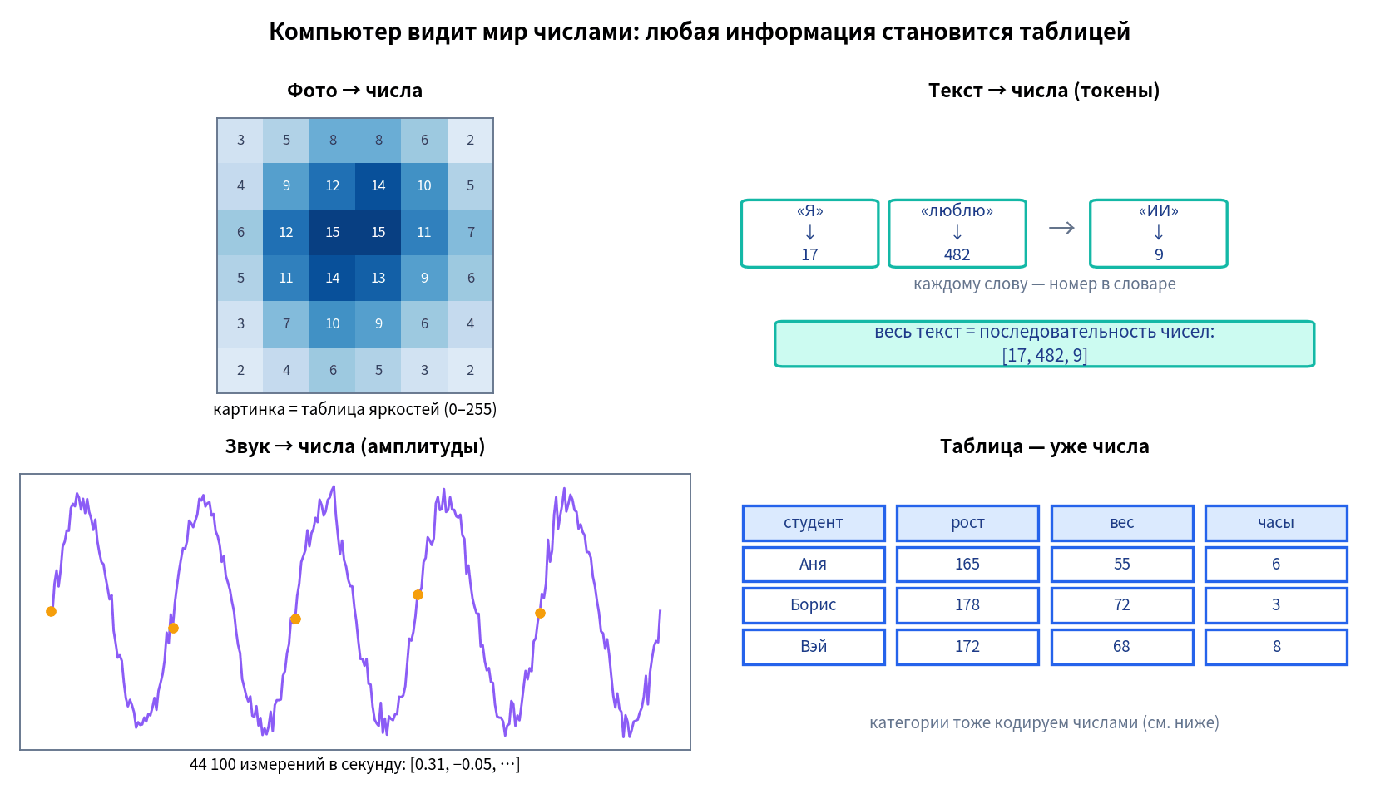

Разберём каждый случай:

- **Фото.** Чёрно-белая картинка — таблица яркостей: число 0 — чёрный, 255 — белый. Цветное фото — три такие таблицы (красный, зелёный, синий каналы). Фото 12 Мп — это 36 миллионов чисел.
- **Текст.** Словарь назначает каждому слову или части слова номер-токен. «Я люблю ИИ» → [17, 482, 9]. Современные модели работают именно с последовательностями таких номеров (лекция 7).
- **Звук.** Микрофон измеряет давление воздуха 44 100 раз в секунду; каждое измерение — число. Минута речи — 2,6 миллиона чисел.
- **Категории.** «Город: Пекин / Шанхай / Гуанчжоу» нельзя просто заменить на 1/2/3 — модель решит, что Шанхай «больше» Пекина. Для категорий используют one-hot кодирование: Пекин = [1,0,0], Шанхай = [0,1,0], Гуанчжоу = [0,0,1].

> **Ключевая мысль курса:** все ИИ-системы, которые мы изучим, — это математика над таблицами чисел. Нет «магического понимания картинок»: есть очень умная обработка числовых таблиц.



### 🔍 Пиксель «под лупой»: фильтры — это арифметика

Рассмотрите любое чёрно-белое фото сильным увеличением: вы увидите сетку серых квадратиков. Каждый квадратик — одно число: **0** — чёрный, **128** — серый, **255** — белый.

Отсюда знаменитые эффекты редактора — буквально одна формула над таблицей яркости:

- **Негатив:** `новое = 255 − старое` (пиксель 100 → 155);
- **Ярче в 1,5 раза:** умножить все числа на 1,5 и обрезать всё, что больше 255;
- **Чёрно-белый фильтр цветного фото:** усреднить три канала R, G, B.

Всё «волшебство» фильтров в телефоне — умная арифметика над числами яркости. Убедимся сами: на практике 7 вы напишете собственный фильтр.


## 3. Математический минимум: три кита

Весь курс держится на трёх понятиях: **вектор** (описание объекта), **матрица** (таблица объектов и преобразования) и **расстояние** (мера похожести). Плюс **вероятность** — она нужна для оценок неопределённости.



## 📌 Что такое вектор (向量)?

**Вектор** — это просто **список чисел**, описывающих один объект.

### Примеры из жизни:

| Объект | Вектор признаков | Что описывает |
|--------|------------------|---------------|
| Студент | `[18, 175, 65, 85]` | возраст, рост (см), вес (кг), средний балл |
| Квартира | `[45, 2, 5, 7.5]` | площадь (м²), число комнат, этаж, расстояние до метро (км) |
| Фотография 28×28 | `[78, 120, 0, 255, ...]` (784 числа) | яркость каждого пикселя |
| Оценки студента | `[78, 92, 65, 88, 71]` | математика, Python, физика, английский, история |

### Почему это важно?

Любой объект в ИИ — это вектор. Модель ИИ учится понимать объекты, работая с их векторами.

<div style='background-color: #FFF3E0; padding: 15px; border-left: 5px solid #F57C00; margin: 20px 0;'>
<b>🔑 Запомните:</b> Вектор = один объект, описанный числами.
</div>

## 📌 Что такое матрица (矩阵)?

**Матрица** — это **таблица векторов**, то есть много объектов, записанных друг под другом.

### Пример: оценки пяти студентов по двум предметам

$$\begin{bmatrix}
78 & 85 \\
92 & 70 \\
65 & 90 \\
88 & ? \\
71 & 66
\end{bmatrix}$$

- **Строки** = студенты (каждая строка — вектор оценок одного студента)
- **Столбцы** = предметы (математика и Python)
- Знак «?» означает пропущенное значение — его нужно заполнить (об этом на Практике 2)

### Где встречаются матрицы?

| Что | Матрица |
|-----|--------|
| Фотография | таблица пикселей (высота × ширина × 3 цвета) |
| Таблица Excel | строки — записи, столбцы — признаки |
| Набор данных для ИИ | тысячи объектов, каждый описан десятками признаков |

<div style='background-color: #E8F5E9; padding: 15px; border-left: 5px solid #388E3C; margin: 20px 0;'>
<b>🔑 Запомните:</b> Матрица = много объектов, каждый в своей строке.
</div>

## ⚙️ Умножение матрицы на вектор = взвешенная сумма

Это **самая важная операция** во всём курсе. Именно так «считает» один нейрон!

### Идея

Представьте, что итоговая оценка студента считается так:
- **30%** — оценка по математике
- **70%** — оценка по Python

Для первого студента:

$$\text{Итог} = 0.3 \times 78 + 0.7 \times 85 = 23.4 + 59.5 = 82.9$$

Числа 0.3 и 0.7 называются **весами (权重)**. Они показывают, насколько важен каждый признак.

### Формула в общем виде

$$\text{Результат} = w_1 \cdot x_1 + w_2 \cdot x_2 + \dots + w_n \cdot x_n$$

где:
- $x_1, x_2, \dots, x_n$ — **входы** (признаки объекта)
- $w_1, w_2, \dots, w_n$ — **веса** (важность каждого признака)

<div style='background-color: #FFEB3B; padding: 15px; border-left: 5px solid #F57F17; margin: 20px 0;'>
<b>💡 Ключевая идея:</b> Взвешенная сумма — это «среднее с учётом важности». То, что важнее, получает больший вес.
</div>

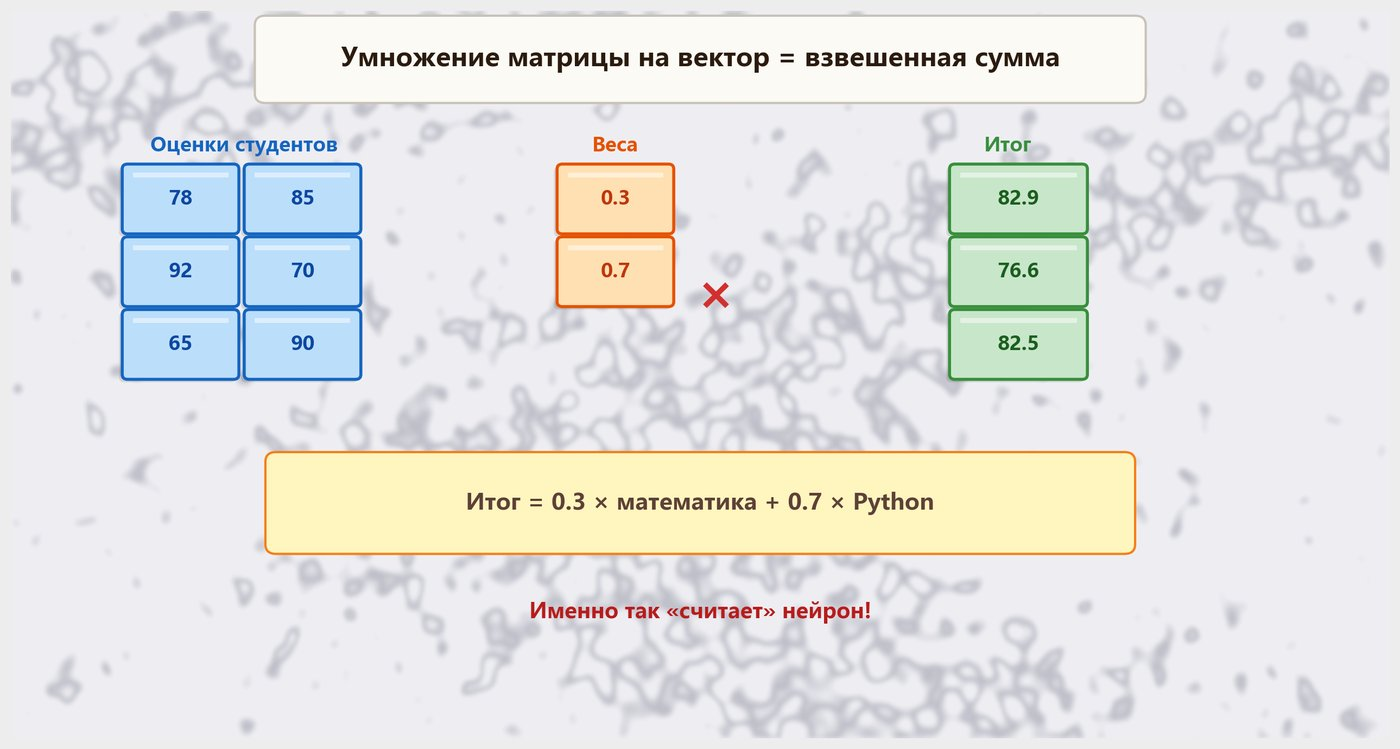

На картинке:
- **Синяя матрица** — оценки трёх студентов по двум предметам
- **Оранжевый вектор** — веса [0.3, 0.7]
- **Зелёный вектор** — итоговые оценки после умножения

Каждая строка матрицы умножается на вектор весов — получается одно число.

## 🧠 Как это связано с нейронами?

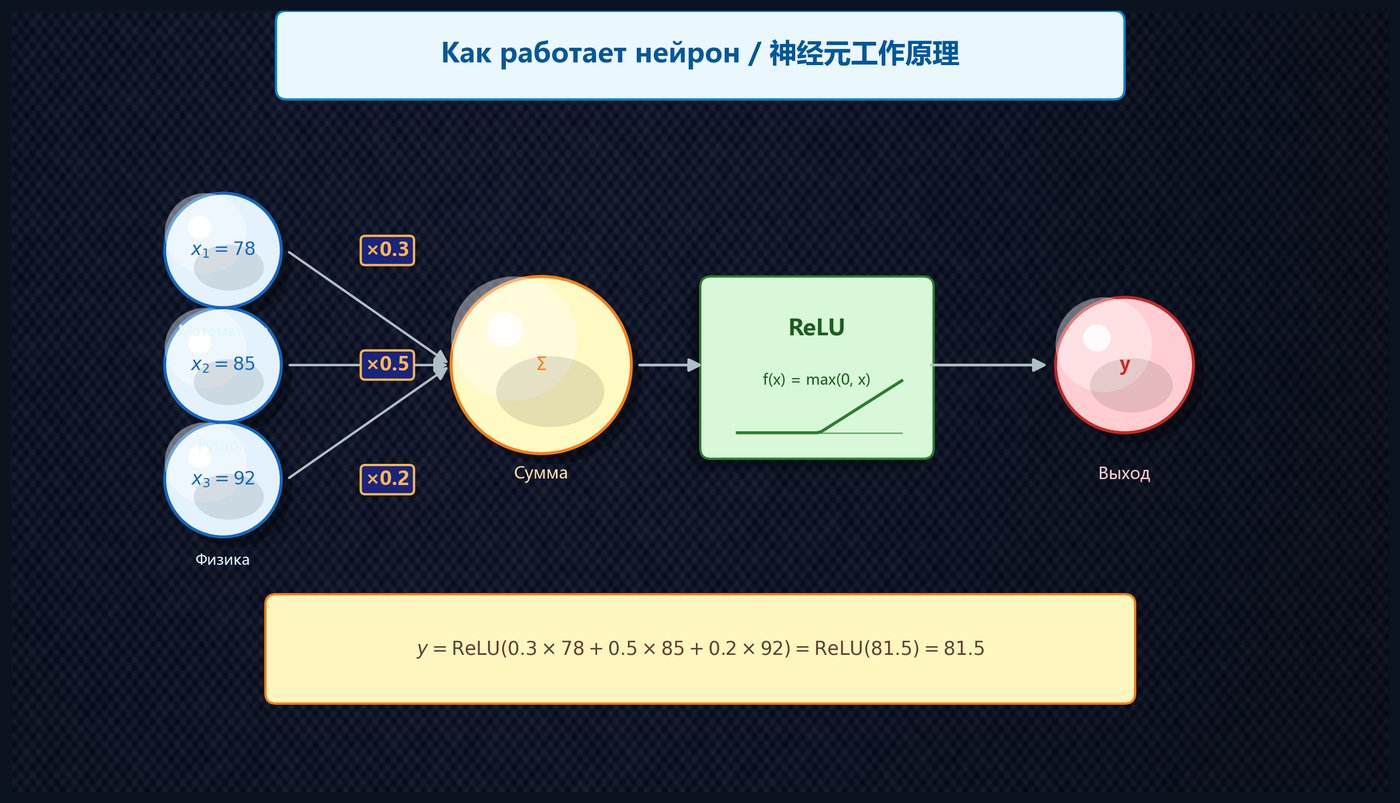

### Как работает нейрон (по шагам):

1. **Входы (x₁, x₂, x₃)** — признаки объекта (например, оценки студента)
2. **Веса (w₁, w₂, w₃)** — насколько важен каждый признак (например, 0.3, 0.5, 0.2)
3. **Сумматор (Σ)** — считает взвешенную сумму: $z = w_1 x_1 + w_2 x_2 + w_3 x_3$
4. **Функция активации (ReLU)** — «отрицательное обнули, положительное оставь»: $y = \max(0, z)$
5. **Выход (y)** — результат работы нейрона

### Пример:

$$y = \text{ReLU}(0.3 \times 78 + 0.5 \times 85 + 0.2 \times 92) = \text{ReLU}(81.5) = 81.5$$

<div style='background-color: #E1F5FE; padding: 15px; border-left: 5px solid #0288D1; margin: 20px 0;'>
<b>💡 Вывод:</b> Нейрон — это просто взвешенная сумма. Вся мощь нейросетей — в миллионах таких нейронов, соединённых вместе. Об этом — на лекциях 5 и 6.
</div>

## 💻 Пример кода: умножение матрицы на вектор

```python
import numpy as np

# Матрица оценок (3 студента, 2 предмета)
grades = np.array([
    [78, 85],  # Студент 1: математика, Python
    [92, 70],  # Студент 2
    [65, 90]   # Студент 3
])

# Веса: 30% математика, 70% Python
weights = np.array([0.3, 0.7])

# Умножение матрицы на вектор (оператор @)
final_scores = grades @ weights

print('Итоговые оценки:')
for i, score in enumerate(final_scores, 1):
    print(f'  Студент {i}: {score:.1f}')
```

**Результат:**
```
Итоговые оценки:
  Студент 1: 82.9
  Студент 2: 76.6
  Студент 3: 82.5
```

### Что произошло?

- Студент 1: $0.3 \times 78 + 0.7 \times 85 = 82.9$ ← высокий балл за Python «вытянул» оценку
- Студент 2: $0.3 \times 92 + 0.7 \times 70 = 76.6$ ← отличный по математике, но слабый по Python — итог ниже
- Студент 3: $0.3 \times 65 + 0.7 \times 90 = 82.5$ ← слабый по математике, но отличный по Python

<div style='background-color: #E8F5E9; padding: 15px; border-left: 5px solid #388E3C; margin: 20px 0;'>
<b>💡 Вывод:</b> Оператор <code>@</code> в NumPy — это умножение матрицы на вектор. Очень удобно! Именно так «считает» нейрон.
</div>

### 3.1. Вектор: описание объекта, косинусное  расстояние (мера похожести объектов)

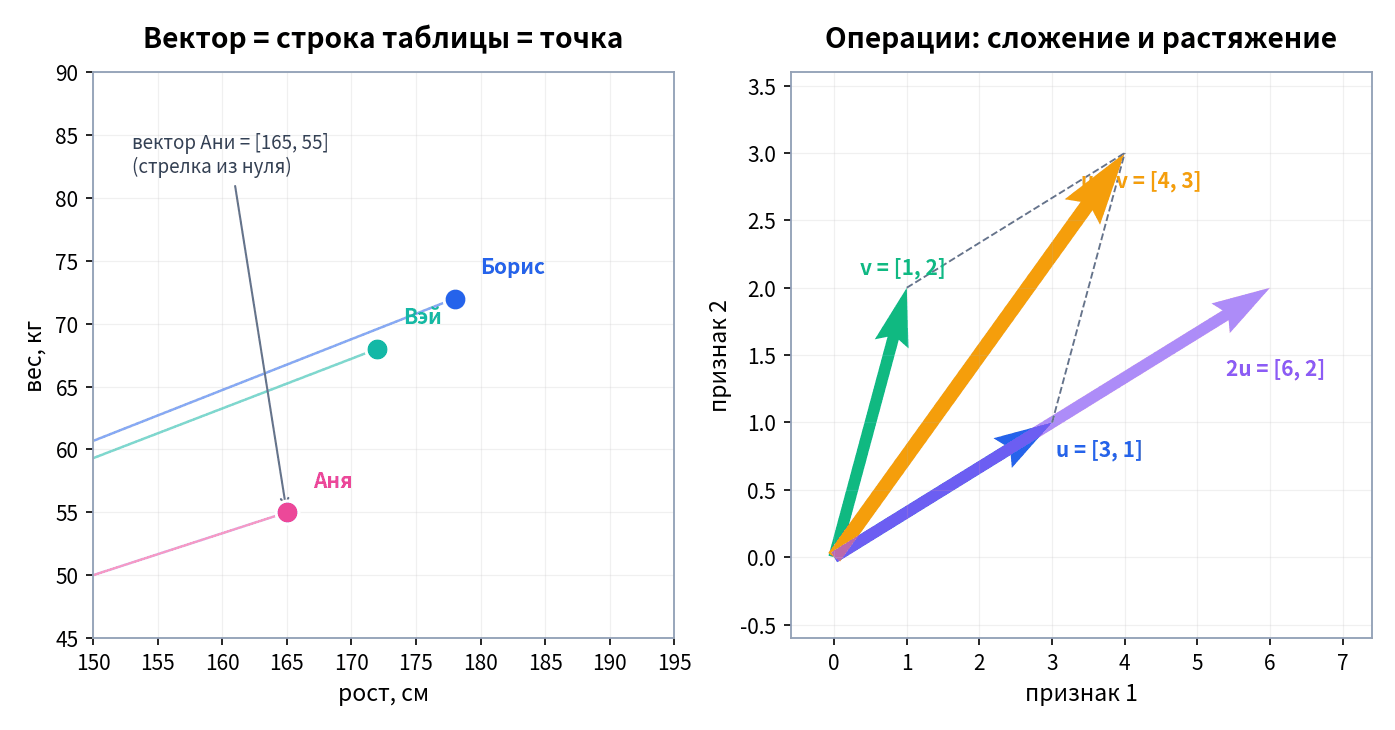

**Вектор** (向量) — упорядоченный набор чисел: $\mathbf{x} = [x_1, x_2, \dots, x_n]$. Строка таблицы «Аня: рост 165, вес 55, готовилась 6 часов» — это вектор $[165, 55, 6]$, он же — точка в 3-мерном пространстве признаков.

Операции:
- **Сложение** $\mathbf{u} + \mathbf{v}$ — по компонентам: $[3,1] + [1,2] = [4,3]$. Геометрически — «дойти по u, затем по v».
- **Умножение на число** $2\mathbf{u}$ — растяжение: $[6, 2]$.
- **Скалярное произведение** $\mathbf{u} \cdot \mathbf{v} = \sum_i u_i v_i$ — «похожесть направлений». Из него получают **косинусное сходство**:

$$\cos(\mathbf{u}, \mathbf{v}) = \frac{\mathbf{u} \cdot \mathbf{v}}{|\mathbf{u}| \, |\mathbf{v}|} \in [-1, 1]$$

Косинусное сходство — рабочая лошадка рекомендательных систем и поиска: «близко к 1 — интересы совпадают, близко к 0 — независимы». Проверим в ячейке ниже.


In [ ]:
import numpy as np

anya    = np.array([5, 1, 4, 1, 5])   # оценки фильмов по жанрам: [боевик, драма, комедия, ужасы, фантастика]
boris   = np.array([4, 2, 5, 1, 4])   # похожие вкусы
chen    = np.array([1, 5, 1, 5, 1])   # противоположные вкусы

cos = lambda a, b: a @ b / (np.linalg.norm(a) * np.linalg.norm(b))
print(f"Аня × Борис: cos = {cos(anya, boris):.2f}  → похожи, рекомендации совпадут")
print(f"Аня × Чэнь:  cos = {cos(anya, chen):.2f}  → вкусы разные, рекомендации разные")

Аня × Борис: cos = 0.97  → похожи, рекомендации совпадут
Аня × Чэнь:  cos = 0.40  → вкусы разные, рекомендации разные


### 3.2. Матрица: таблица объектов и машина преобразований

**Матрица** (矩阵) — прямоугольная таблица чисел: строки — объекты, столбцы — признаки. Вся обучающая выборка — одна матрица $X$ размера «объекты × признаки».


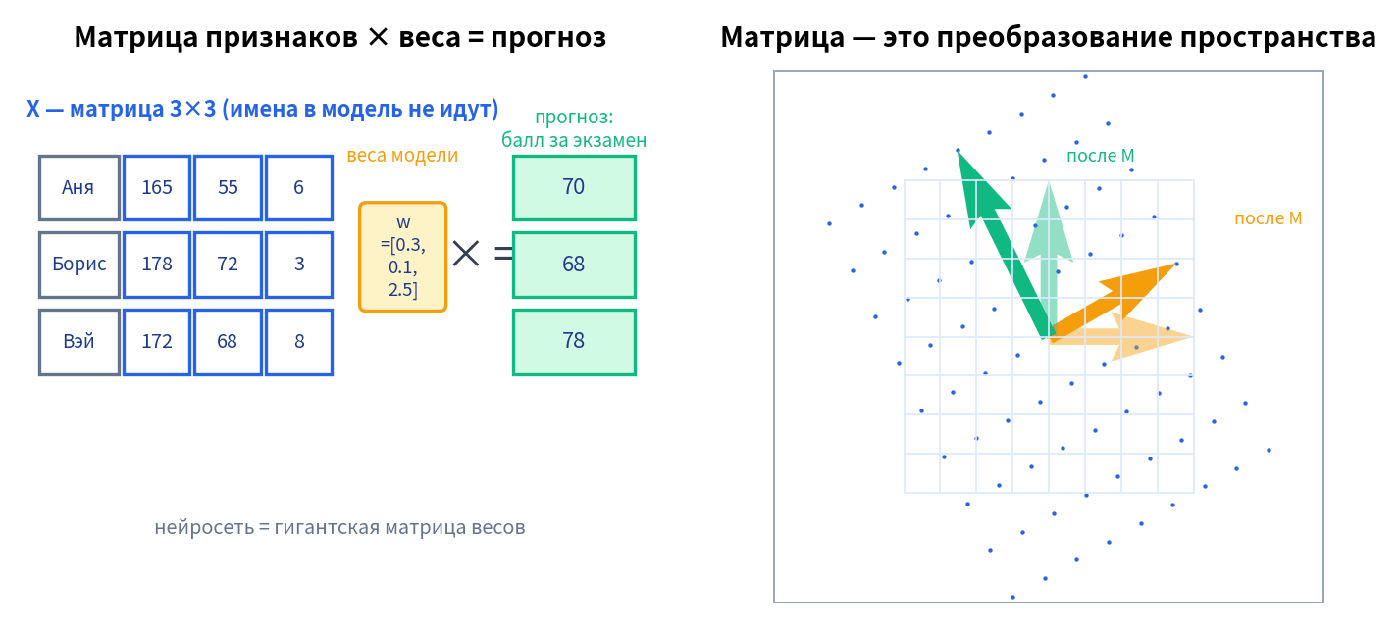

Слева — главное соотношение машинного обучения «на пальцах»: матрица данных $X$, умноженная на вектор весов $\mathbf{w}$, даёт вектор прогнозов. Одна операция $X\mathbf{w}$ — прогнозы для всех объектов сразу. **Нейросеть — это просто очень много таких умножений, перемежаемых нелинейностями** (лекция 5).

Справа — вторая ипостась матрицы: **преобразование пространства**. Умножение на матрицу поворачивает и растягивает всю плоскость. Слои нейросети делают ровно это: каждый слой «выкручивает» пространство признаков так, чтобы в конце классы стало легко разделить прямой линией.

### 3.3. Расстояние: «близко = похоже»

Самая известная мера — **евклидово расстояние** (欧氏距离), «по линейке»:

$$d(\mathbf{u}, \mathbf{v}) = \sqrt{\sum_i (u_i - v_i)^2} = |\mathbf{u} - \mathbf{v}|$$


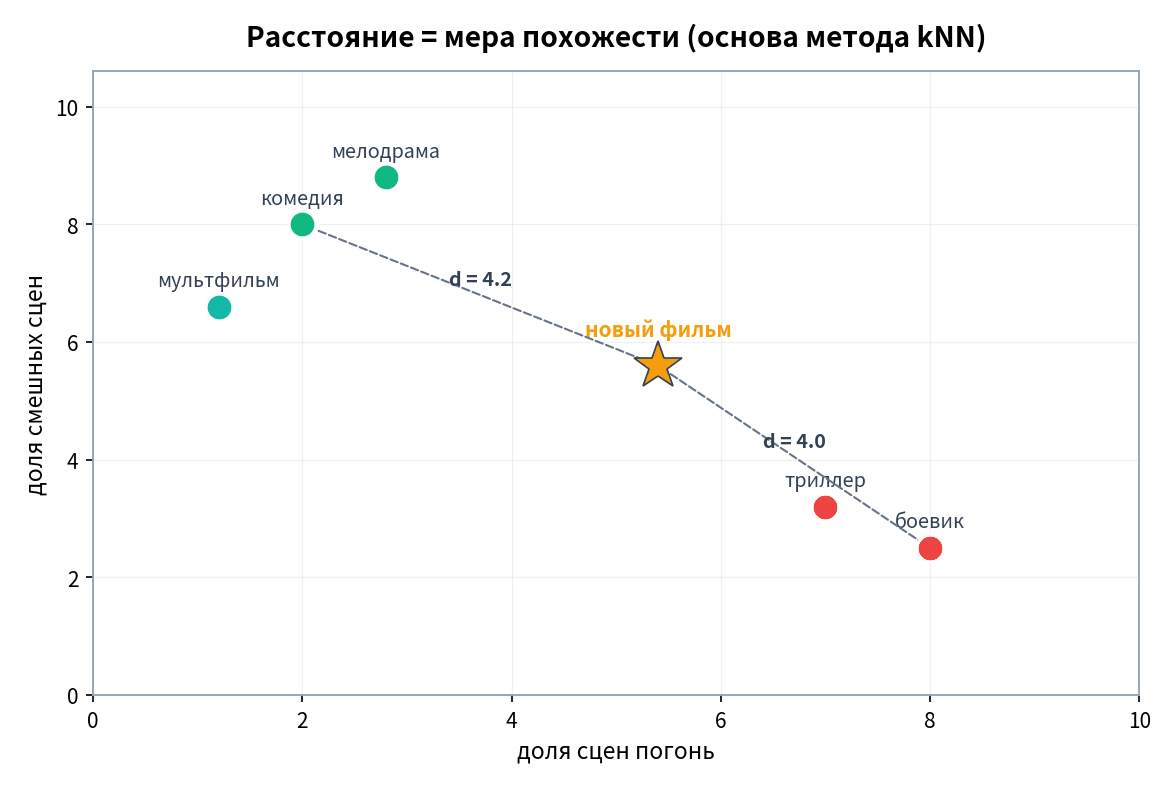

Идея на рисунке — сердце метода ближайших соседей (kNN) из лекции 4: если новый фильм близок к боевикам — он, скорее всего, боевик. Одна тонкость, о которой нельзя забывать: **масштаб признаков**. Если рост меряется в сантиметрах (150–190), а доход — в тысячах юаней (3–50), расстояние будет полностью определено доходом. Поэтому признаки обычно **нормируют** — приводят к сравнимым масштабам (стандартизация: вычесть среднее, поделить на разброс; это делает `StandardScaler` из scikit-learn).


In [ ]:
# расстояния и роль масштаба признаков
a = np.array([170, 60])      # рост (см), доход (тыс.)
b = np.array([175, 20])
print(f"d(а, b) = {np.linalg.norm(a - b):.1f}  → доход доминирует: 40 из 40.4")

from sklearn.preprocessing import StandardScaler
Xs = StandardScaler().fit_transform(np.array([[170, 60], [175, 20]]))
print(f"после нормировки d = {np.linalg.norm(Xs[0] - Xs[1]):.2f}  → оба признака важны одинаково")

d(а, b) = 40.3  → доход доминирует: 40 из 40.4
после нормировки d = 2.83  → оба признака важны одинаково



### 📏 Пример «под микроскопом»: чайник против термопота

Опишем два товара векторами из трёх признаков: **чайник** = (мощность 2200 Вт, объём 1,7 л, цена 199 юаней), **термопот** = (800, 4,0, 399). Сравнивать «в лоб» неудобно: признаки в разных единицах, и цена «перекрикивает» объём.

Приём **нормализации** — поделить каждый признак на максимум столбца:

| Товар | Мощность | Объём | Цена |
|---|---|---|---|
| чайник | 2200/2200 = **1,00** | 1,7/4,0 = **0,42** | 199/399 = **0,50** |
| термопот | 800/2200 = **0,36** | 4,0/4,0 = **1,00** | 399/399 = **1,00** |

Теперь все числа от 0 до 1, и евклидово расстояние (школьная формула: корень из суммы квадратов разностей) даёт осмысленную меру «непохожести». Рядом с термопотом рекомендательная система покажет не чайник, а **другой термопот** — тот, чей вектор ближе. Вся рекомендательная математика начинается с этой таблички.


### 🎯 Что важно запомнить

- **Размерность вектора** — сколько в нём чисел (у нас 3: рост, вес, возраст)
- **Размерность матрицы** — строки × столбцы (у нас 3×3)
- **Операция `@`** в NumPy — это умножение матрицы на вектор, то есть взвешенная сумма
- **`axis=0`** — операция по столбцам (по признакам), **`axis=1`** — по строкам (по студентам)

> 💡 В нейронной сети каждый нейрон делает именно такую операцию: берёт входной вектор, умножает на вектор весов и складывает. Разница только в том, что весов не три, а сотни или тысячи.

## 4. Вероятность и статистика: язык неопределённости

### 🎲 Основные понятия

- **Вероятность (概率)** — доля случаев, когда событие происходит (от 0 до 1)
- **Условная вероятность ( 条件概率)** — вероятность события при условии другого
- **Среднее (平均数)** — «типичное» значение
- **Разброс (方差/标准差)** — насколько значения отличаются от среднего


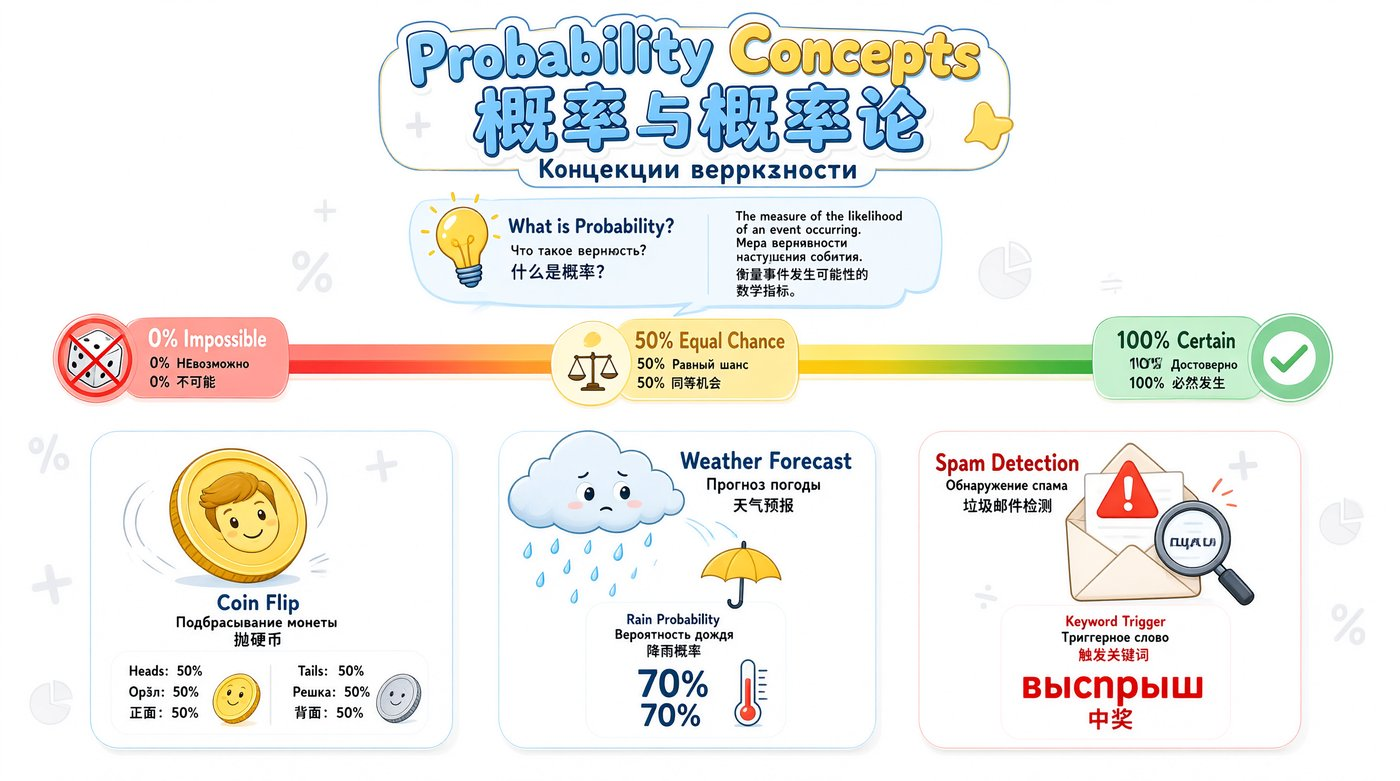

### 4.1. Вероятность как частота
## 📌 Что такое вероятность (概率)?

**Вероятность** — это число от **0 до 1**, которое показывает, насколько мы уверены, что событие произойдёт.

**Вероятность** (概率) события — предел частоты при большом числе испытаний: если из 1000 писем 200 — спам, то $P(\text{спам}) = 0{,}2$. Вероятности всех исходов в сумме дают 1.

| Значение | Что означает | Пример |
|----------|--------------|--------|
| **0** | Невозможно | Завтра солнце взойдёт на западе |
| **0.5** | Равновероятно | Орёл или решка при броске монеты |
| **1** | Точно случится | Завтра солнце взойдёт на востоке |

<div style='background-color: #FFF3E0; padding: 15px; border-left: 5px solid #F57C00; margin: 20px 0;'>
<b>🔑 Запомните:</b> Вероятность = насколько мы уверены в событии. 0 — точно нет, 1 — точно да.
</div>


| Ситуация | Вероятность | Пояснение |
|---|---|---|
| 🪙 Орёл при броске монеты | 50% (0.5) | Два равновероятных исхода |
| 🌧️ Дождь завтра по прогнозу | 70% (0.7) | На основе данных прошлых лет |
| 📧 Письмо — спам, если есть слово «выигрыш» | высокая | Условная вероятность |

---

## 📧 Условная вероятность: пример со спамом

### Задача

Какова вероятность, что письмо — спам, **если** в нём есть слово «выигрыш»?

### Решение

Это **условная вероятность (条件概率)**: $P(\text{спам} | \text{слово «выигрыш»})$

**Данные:**
- Из 1000 писем со словом «выигрыш» 900 оказались спамом
- Значит: $P(\text{спам} | \text{«выигрыш»}) = \frac{900}{1000} = 0.9$

### Зачем это нужно в ИИ?

Фильтр спама считает такие вероятности для разных слов и признаков:

| Признак | Вероятность спама |
|---------|-------------------|
| Слово «выигрыш» | 0.9 |
| Много восклицательных знаков | 0.7 |
| Странная ссылка | 0.8 |
| Письмо от знакомого | 0.1 |

Модель объединяет эти вероятности и решает: спам или не спам.

<div style='background-color: #E1F5FE; padding: 15px; border-left: 5px solid #0288D1; margin: 20px 0;'>
<b>💡 Вывод:</b> Вероятность — это основа машинного обучения. Модели предсказывают вероятности разных исходов, а не твёрдые ответы.
---


### 4.2. Условная вероятность и теорема Байеса

**Условная вероятность** $P(A \mid B)$ — вероятность $A$ при известном $B$. Теорема Байеса переворачивает условие:

$$P(A \mid B) = \frac{P(B \mid A) \, P(A)}{P(B)}$$


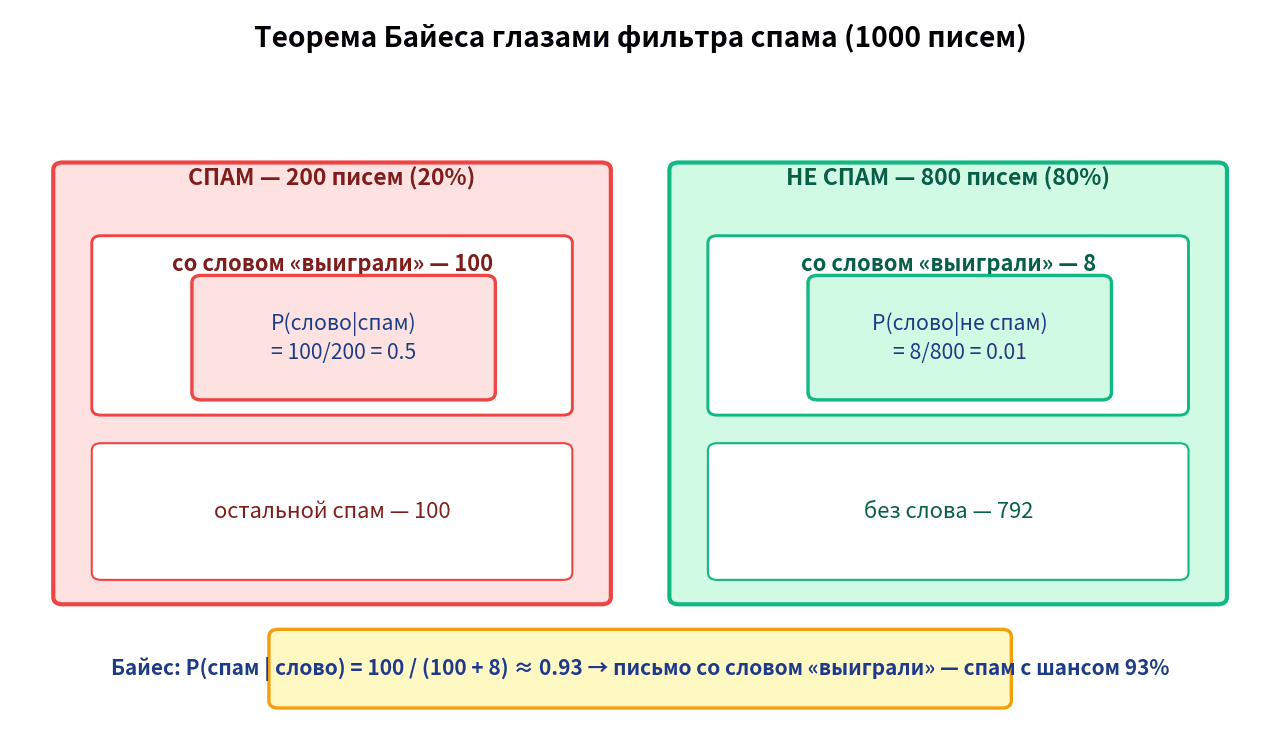

Читаем рисунок как фильтр: из 1000 писем спама — 200, и в половине из них (100) есть слово «выиграли»; среди нормальных писем (800) слово встретилось в 8. Вопрос фильтра — **обратный** к статистике: дано слово, какова вероятность спама?

$$P(\text{спам} \mid \text{слово}) = \frac{100}{100 + 8} \approx 0{,}93$$

Это и есть наивный байесовский классификатор — первая ласточка машинного обучения, работавшая в почтовых фильтрах 1990-х. Слово «наивный» — потому что предполагает независимость слов (они, конечно, зависимы), но на практике работает на удивление хорошо.



### 4.3. Среднее, медиана, разброс

## 📊 Среднее (均值) и разброс (方差)

Два важнейших понятия статистики.

### Среднее (均值, mean)

**Среднее** — это «типичное» значение. Складываем все числа и делим на их количество.

$$\bar{x} = \frac{x_1 + x_2 + \dots + x_n}{n}$$

**Пример:** Оценки `[7, 8, 6, 9, 5]`

$$\bar{x} = \frac{7 + 8 + 6 + 9 + 5}{5} = \frac{35}{5} = 7$$

### Разброс / дисперсия (方差, variance)

$$\sigma^2 = \frac{1}{N} \sum_{i=1}^{N} (x_i - \mu)^2$$

**Пример:** Сумма квадратов отклонений: $$(7 - 7)^2 = 0 +(8 - 7)^2 = 1 + (6 - 7)^2 = 1 + (9 - 7)^2 = 4 + (5 - 7)^2 = 4$$
Дисперсия
$$
\sigma^2 = \frac{10}{5} = 2
$$


**Разброс** показывает, насколько значения отличаются от среднего.

- **Малый разброс** — все значения близки к среднему (оценки `[7, 7.5, 6.5, 7.2, 6.8]`)
- **Большой разброс** — значения сильно различаются (оценки `[3, 9, 2, 8, 4]`)

В обоих случаях среднее около 7, но во втором случае оценки «скачут».

### Стандартное отклонение (标准差, std)

$\sigma = \sqrt{\frac{\sum_{i=1}^{N}(x_i - \mu)^2}{N}}$

Это корень из дисперсии. Показывает «типичное отклонение» от среднего в тех же единицах, что и данные.

**Пример**  Генеральное стандартное отклонение:
$$
\sigma = \sqrt{2} \approx 1{,}41
$$


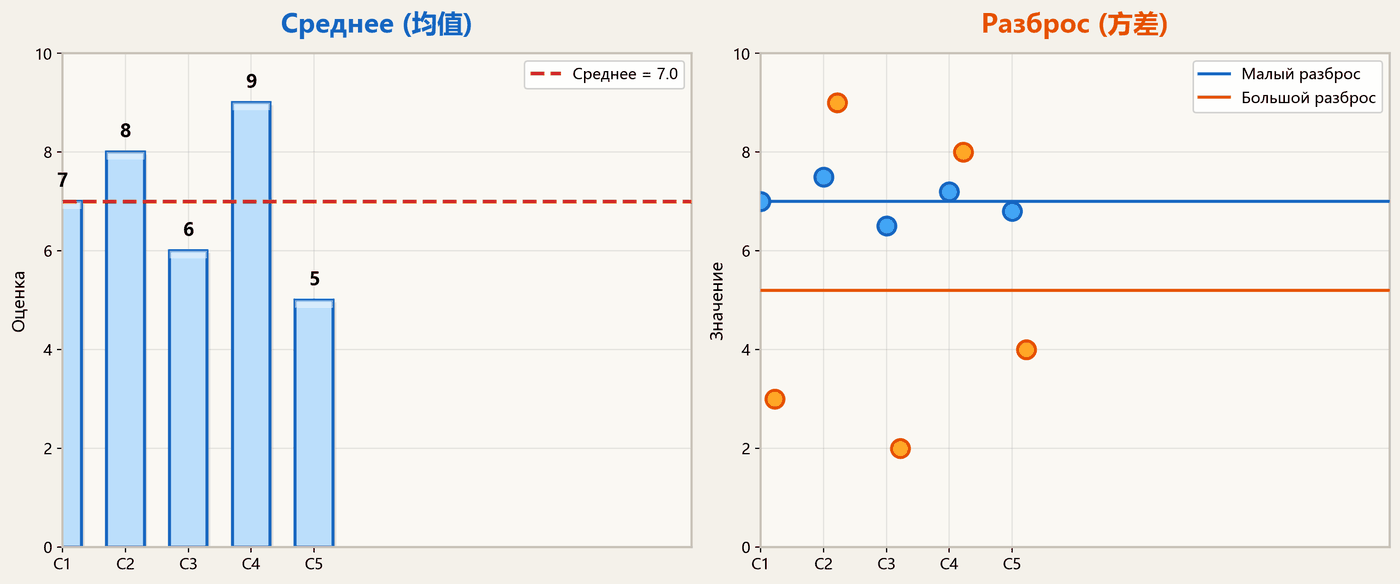

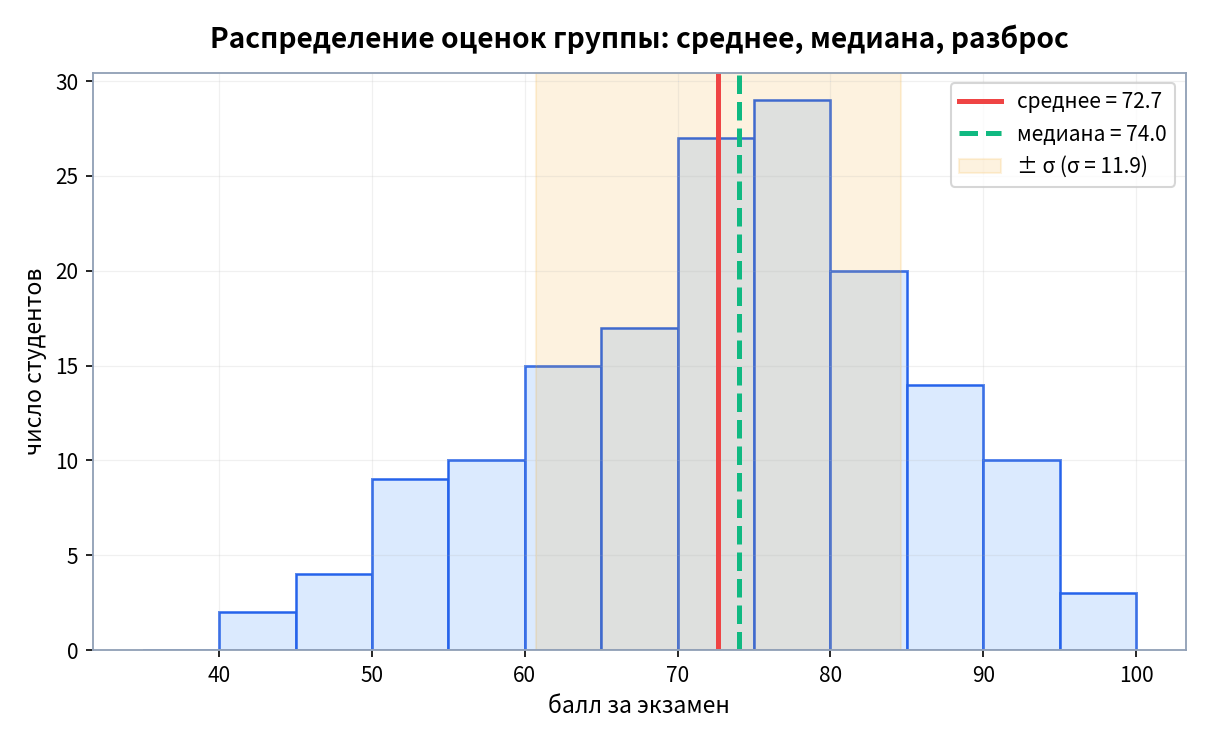

- **Среднее** (均值) — сумма, делённая на количество: «центр масс».
- **Медиана** (中位数) — значение ровно в середине отсортированного ряда: устойчива к выбросам. Если один студент написал на 100, а группа — на 60, среднее подпрыгнет, медиана почти не шевельнётся.
- **Стандартное отклонение σ** (标准差) — средний «разброс» вокруг среднего: насколько типично отклонение. Правило «68–95–99,7» для колоколообразных данных: ±1σ содержит ≈68% значений, ±2σ — 95%.

**❓ Вопрос:** зарплаты в компании: девять сотрудников по 20 тыс. и директор 500 тыс. Что лучше описывает «типичную» зарплату — среднее или медиана? *(Медиана: среднее = 68 тыс. исказит картину.)*



### 📊 Среднее и разброс на примере оценок

Оценки группы: [78, 92, 65, 88, 71, 95, 83]

- **Среднее:** (78+92+65+88+71+95+83) / 7 = 81.7
- **Разброс (стандартное отклонение):** насколько оценки отличаются от среднего
- **Минимум/максимум:** 65 и 95

In [ ]:
# Простая демонстрация вероятности на монете
import numpy as np

# Бросаем монету 1000 раз: 0 = орёл, 1 = решка
flips = np.random.randint(0, 2, size=1000)
print('Всего бросков:', len(flips))
print('Орлов (0):', (flips == 0).sum(), '→ доля:', (flips == 0).mean())
print('Решек (1):', (flips == 1).sum(), '→ доля:', (flips == 1).mean())

# Среднее и разброс оценок студентов
scores = np.array([78, 92, 65, 88, 71, 95, 83])
print('\nОценки:', scores)
print('Среднее:', scores.mean())
print('Разброс (стандартное отклонение):', scores.std())
print('Минимум:', scores.min(), '| Максимум:', scores.max())
print('Медиана:', np.median(scores))

# Условная вероятность: спам при наличии слова «выигрыш»
total_emails = 10000
spam_emails = 2000
emails_with_word = 1500
spam_with_word = 1400

p_spam = spam_emails / total_emails
p_word_given_spam = spam_with_word / spam_emails
p_spam_given_word = spam_with_word / emails_with_word

print(f'\nВероятность спама: {p_spam:.1%}')
print(f'Вероятность слова «выигрыш» при спаме: {p_word_given_spam:.1%}')
print(f'Вероятность спама при слове «выигрыш»: {p_spam_given_word:.1%}')

Всего бросков: 1000
Орлов (0): 513 → доля: 0.513
Решек (1): 487 → доля: 0.487

Оценки: [78 92 65 88 71 95 83]
Среднее: 81.71428571428571
Разброс (стандартное отклонение): 10.222025039999039
Минимум: 65 | Максимум: 95
Медиана: 83.0

Вероятность спама: 20.0%
Вероятность слова «выигрыш» при спаме: 70.0%
Вероятность спама при слове «выигрыш»: 93.3%


### 🎯 Что важно запомнить

- **Вероятность** всегда от 0 до 1 (или от 0% до 100%)
- **Среднее** чувствительно к выбросам: одна оценка 20 сильно снизит среднее
- **Медиана** — значение посередине отсортированного списка, устойчива к выбросам
- **Условная вероятность** — основа байесовских методов и фильтров спама
  
<div style='background-color: #F3E5F5; padding: 15px; border-left: 5px solid #7B1FA2; margin: 20px 0;'>
<b>💡 Совет:</b> В ИИ мы часто смотрим на среднее и разброс, чтобы понять, «нормальные» ли данные. Если разброс огромный — возможно, в данных есть ошибки или выбросы.
</div>

### 4.4. Корреляция: связь без причины

**Корреляция**
показывает степень линейной связи между двумя переменными. Чаще всего используют коэффициент корреляции Пирсона.

## Формула

Для двух переменных $X$ и $Y$:
$$
r_{XY} = \frac{\sum_{i=1}^{n}(x_i - \bar{x})(y_i - \bar{y})}{\sqrt{\sum_{i=1}^{n}(x_i - \bar{x})^2} \sqrt{\sum_{i=1}^{n}(y_i - \bar{y})^2}}
$$

- $\bar{x}, \bar{y}$ — средние значения.
- Числитель — ковариация (совместная изменчивость).
- Знаменатель — произведение стандартных отклонений.

## Диапазон значений

$-1 \le r \le 1$:
- $r = 1$ — идеальная положительная линейная связь (когда $X$ растёт, $Y$ тоже растёт).
- $r = -1$ — идеальная отрицательная линейная связь (когда $X$ растёт, $Y$ падает).
- $r \approx 0$ — линейной связи нет (но может быть нелинейная!).

## Важные оговорки

- **Корреляция ≠ причинность.** Если $X$ и $Y$ сильно коррелируют, это не значит, что $X$ вызывает $Y$.
- **Чувствительность к выбросам.** Один аномальный пункт может сильно исказить $r$.
- **Линейность.** Коэффициент Пирсона отражает только линейную связь. Связь может быть сильной, но нелинейной — тогда $r$ будет близок к 0.

---

## Как интерпретировать силу связи (ориентиры)

| Значение | Интерпретация |
|----------|---------------|
| $|r| \ge 0{,}7$ | Сильная связь |
| $0{,}3 \le |r| < 0{,}7$ | Умеренная связь |
| $|r| < 0{,}3$ | Слабая или отсутствует линейная связь |


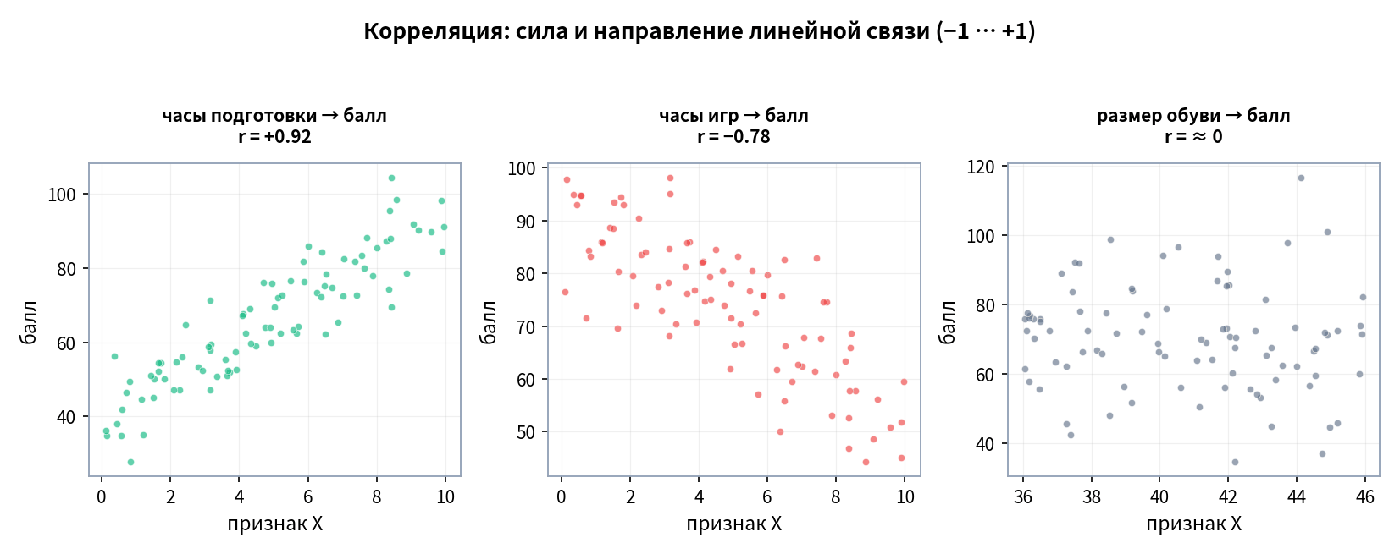

**Коэффициент корреляции Пирсона** $r \in [-1, 1]$ измеряет силу линейной связи: знак — направление, модуль — теснота. Правило чтения: $|r| > 0{,}7$ — сильная связь, $0{,}3$–$0{,}7$ — заметная, $< 0{,}3$ — слабая.

**Две ловушки:**
1. **Корреляция ≠ причинность.** Продажи мороженого коррелируют с утоплениями — но причина обеих третья: жаркое лето. Классические «ложные корреляции»: количество фильмов с Николасом Кейджем и число утонувших в бассейне ($r \approx 0{,}67$).
2. **Только линейная связь.** Связь «доза–эффект» по параболе при $r \approx 0$ — связь есть, коэффициент её не видит. Поэтому всегда рисуют диаграмму рассеяния, прежде чем судить.


## 🎬 Видеоматериалы: линейная алгебра, вероятность и математика
Вся серия «Суть линейной алгебры» 3Blue1Brown (рус. озвучка), теорема Байеса, вероятности.

### 🇷🇺 РУС · русскоязычные видео (14)
| № | Видео | Источник | Длит. | Раздел лекции | Доступность |
|---|-------|----------|-------|----------------|---|
| 1 | [Суть линейной алгебры: #1. Векторы [3Blue1Brown]](https://vkvideo.ru/video-55155418_456242113)<br>· ориг.: *Essence of linear algebra #1: Vectors* | Vert Dider (VK/Rutube) | 9 мин | Л2 §3.1: вектор — базовая единица данных | X |
| 2 | [Суть линейной алгебры: №2. Линейная комбинация, оболочка и базис](https://vkvideo.ru/video-55155418_456242128)<br>· ориг.: *Essence of linear algebra #2* | Vert Dider (VK/Rutube) | 10 мин | Л2 §3: векторы, линейная оболочка, базис | X |
| 3 | [Суть линейной алгебры: #3. Линейные преобразования и матрицы](https://vkvideo.ru/video-55155418_456242129)<br>· ориг.: *Essence of linear algebra #3* | Vert Dider (VK/Rutube) | 11 мин | Л2 §3.2: матрица как преобразование данных | X |
| 4 | [Суть линейной алгебры: #4. Произведение матриц, или композиция преобразований](https://rutube.ru/video/637b8bdd956a2817540249950f123368)<br>· ориг.: *Essence of linear algebra #4: Matrix multiplication as composition* | Vert Dider (VK/Rutube) | 10 мин | Л2 §3.2: умножение матриц как последовательное применение преобразований | X |
| 5 | [Суть линейной алгебры: №5. Линейные преобразования в трёх измерениях](https://vkvideo.ru/video-55155418_456242155)<br>· ориг.: *Essence of linear algebra #5: Three-dimensional linear transformations* | Vert Dider (VK/Rutube) | 5 мин | Л2 §3.2: преобразования в трёхмерном пространстве, матрицы 3×3 | X |
| 6 | [Суть линейной алгебры: №6. Определитель](https://vkvideo.ru/video-55155418_456242176)<br>· ориг.: *Essence of linear algebra #6: The determinant* | Vert Dider (VK/Rutube) | 10 мин | Л2 §3: определитель — коэффициент изменения объёма, обратимость преобразования | X |
| 7 | [Суть линейной алгебры: №7. Обратные матрицы, пространство столбцов и нуль-пространство](https://vkvideo.ru/video-55155418_456242187)<br>· ориг.: *Essence of linear algebra #7: Inverse matrices, column space and null space* | Vert Dider (VK/Rutube) | 12 мин | Л2 §3: обратная матрица, ранг, пространства столбцов и нуль-пространство | X |
| 8 | [Суть линейной алгебры: №8. Неквадратные матрицы](https://vkvideo.ru/video-55155418_456242188)<br>· ориг.: *Essence of linear algebra #8* | Vert Dider (VK/Rutube) | 4 мин | Л2 §3: преобразования между размерностями | X |
| 9 | [Суть линейной алгебры: #9. Скалярное произведение](https://vkvideo.ru/video-55155418_456242235)<br>· ориг.: *Essence of linear algebra #9* | Vert Dider (VK/Rutube) | 14 мин | Л2 §3.1–3.3: косинусное сходство, взвешенная сумма | X |
| 10 | [Суть линейной алгебры: №10. Векторное произведение](https://vkvideo.ru/video-55155418_456242263)<br>· ориг.: *Essence of linear algebra #10* | Vert Dider (VK/Rutube) | 9 мин | Л2 §3: векторные операции | X |
| 11 | [Суть линейной алгебры: №11. Векторное произведение и линейные преобразования](https://vkvideo.ru/video-55155418_456242303)<br>· ориг.: *Essence of linear algebra #11* | Vert Dider (VK/Rutube) | 13 мин | Л2 §3: связь операций с матрицами | X |
| 12 | [Вся суть линейной алгебры за 3 часа [3Blue1Brown] (сборник)](https://rutube.ru/video/1cc1bfa1b1aac05253c4812873d4c4a8)<br>· ориг.: *Essence of linear algebra — compilation* | Vert Dider (VK/Rutube) | 2 ч 54 мин | Л2 §3: полная серия для углубления | X |
| 13 | [Теорема Байеса [3Blue1Brown]](https://rutube.ru/video/65f9a7699393f6fb3a4a67acc6219a1f/)<br>· ориг.: *Bayes theorem* | Vert Dider (VK/Rutube) | 15 мин | Л2 §4.2: условная вероятность и теорема Байеса | X |
| 14 | [Вероятности вероятностей: №1. Биномиальное распределение [3Blue1Brown]](https://rutube.ru/video/d9990c1f942eef24636dcc2ef2917a18)<br>· ориг.: *Probabilities of probabilities #1* | Vert Dider (VK/Rutube) | 12 мин | Л2 §4.1: вероятность как частота | X |

### 🇨🇳 中文 · китайскоязычные видео (оригинал в курсиве) (4)
| № | Видео | Источник | Длит. | Раздел лекции | Доступность |
|---|-------|----------|-------|----------------|---|
| 1 | [Линейная алгебра](https://www.bilibili.com/video/BV1EY6FBwE8P?p=10)<br>· ориг.: *10.1-线性代数* | Bilibili · 李沐 | 9 мин | Л2 §3: векторы и матрицы для ИИ | ✓ |
| 2 | [Линейная алгебра: реализация в коде](https://www.bilibili.com/video/BV1EY6FBwE8P?p=11)<br>· ориг.: *11.2-线性代数实现-* | Bilibili · 李沐 | 12 мин | Л2 §3: матрицы и векторы на практике | ✓ |
| 3 | [Производная: понятие и базовые формулы](https://www.bilibili.com/video/BV1BYe4z5E9z?p=2)<br>· ориг.: *002_数学基础_导数的概念和基本公式* | Bilibili · 尚硅谷 | 10 мин | Л2 §3: производные — задел под градиент (Л5) | ✓ |
| 4 | [Скаляры и векторы (математический минимум)](https://www.bilibili.com/video/BV1BYe4z5E9z?p=9)<br>· ориг.: *009_数学基础_标量与向量* | Bilibili · 尚硅谷 | 17 мин | Л2 §3.1: векторы | ✓ |



### 🇬🇧 EN · англоязычные видео (3)
| № | Видео | Источник | Длит. | Раздел лекции | Доступность |
|---|-------|----------|-------|----------------|---|
| 1 | [StatQuest-песенка: матрицы в музыке](https://www.bilibili.com/video/BV1DTmZYgEoB/)<br>· ориг.: *【StatQuest】边听歌边学知识 - 矩阵表示* | Bilibili · StatQuest | 0 мин | Доп.: 18-секундная песенка про матрицы | ✓ |
| 2 | [StatQuest-песенка: собственные значения](https://www.bilibili.com/video/BV1cRAZeAEco)<br>· ориг.: *【StatQuest】一首歌记住特征值* | Bilibili · StatQuest | 0 мин | Доп.: песенка про собственные значения | ✓ |
| 3 | [StatQuest-песенка: умножение матриц](https://www.bilibili.com/video/BV1WSUZYvE1f)<br>· ориг.: *【StatQuest】把数学知识唱成歌 - 矩阵乘法* | Bilibili · StatQuest | 0 мин | Доп.: песенка про умножение матриц | ✓ |


## 5. Python и его экосистема

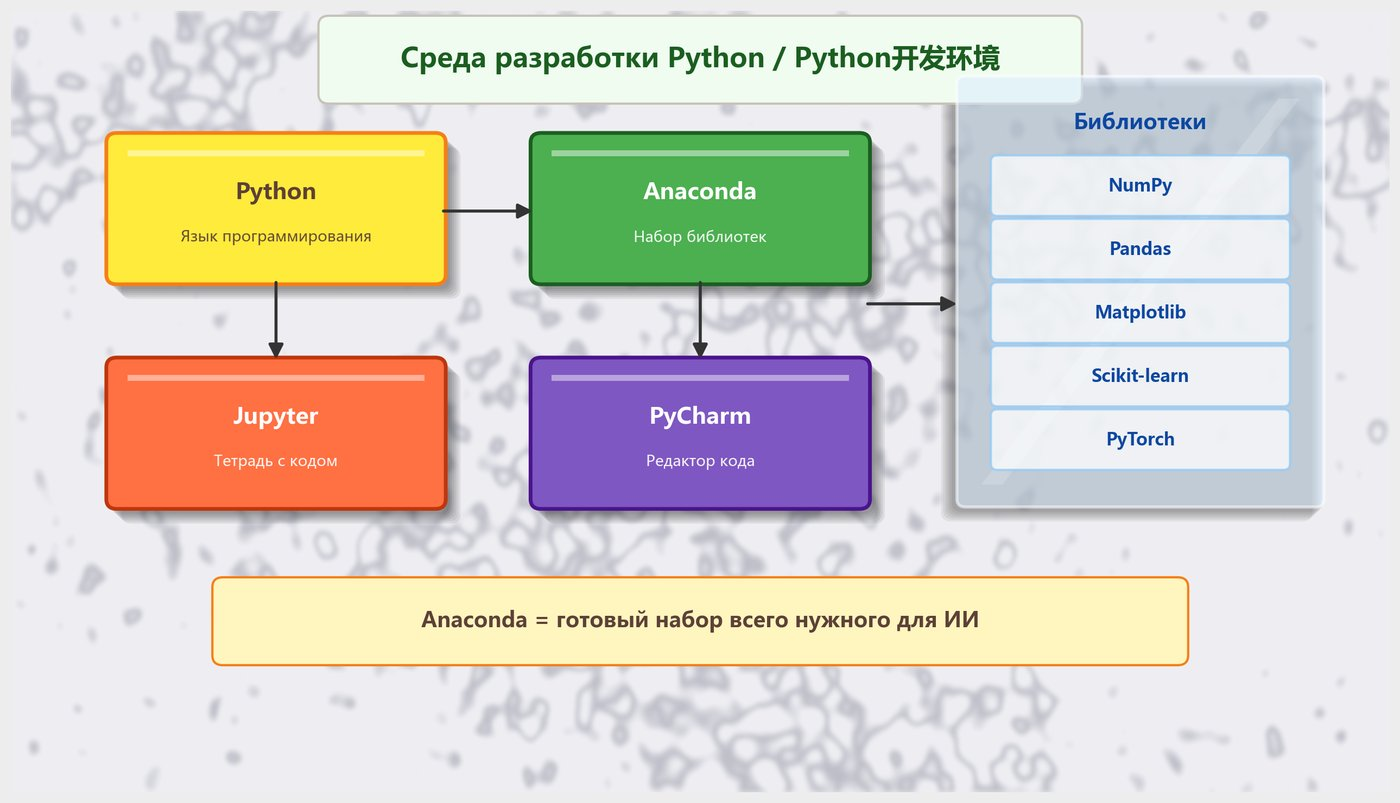

**Python (派森)** — это язык программирования, самый популярный в ИИ.

### Почему именно Python?

| Причина | Объяснение |
|---------|------------|
| **Простой синтаксис** | Код читается почти как английский текст |
| **Огромное количество библиотек** | Для ИИ есть всё: NumPy, Pandas, PyTorch, TensorFlow |
| **Поддержка крупных компаний** | Google, Facebook, Alibaba, Baidu активно используют Python |
| **Сообщество** | Миллионы разработчиков, много учебных материалов |
| **«Клей»**| Python легко связывает быстрые C/С++-библиотеки, поэтому на нём пишут интерфейсы, а тяжёлую математику делают NumPy/PyTorch под капотом.|

### Пример: насколько прост Python

```python
# Напечатать «Привет, мир!»
print('Привет, мир!')

# Сложить два числа
a = 5
b = 3
print(a + b)  # 8
```

In [ ]:
# типы данных, которые встретятся в каждом ноутбуке курса
name  = "Аня"                       # str  — строка
score = 92.5                        # float — дробное
hours = 6                           # int — целое
marks = [80, 75, 92]                # list — список (изменяемый)
point = (165, 55)                   # tuple — кортеж (неизменяемый)
stats = {"mean": 82.3, "std": 11.9} # dict — словарь «ключ: значение»
ok    = score > 90                  # bool — True / False

print(type(name).__name__, type(stats).__name__, ok)
print(f"средний балл из списка: {sum(marks) / len(marks):.1f}")

str dict True
средний балл из списка: 82.3


## 📌 Что такое библиотека (库)?

**Библиотека** — это набор готовых функций, которые кто-то уже написал. Вместо того чтобы писать всё с нуля, мы используем библиотеки.

### Главные библиотеки для ИИ:

| Библиотека | Что делает | Когда используем |
|------------|------------|------------------|
| **NumPy** | Работа с числами и матрицами | Лекции 2, практики 2, 4 |
| **Pandas** | Работа с таблицами (как Excel) | Практики 2, 3, 4 |
| **Matplotlib** | Построение графиков | Все практики |
| **Scikit-learn** | Классические алгоритмы ML | Практики 3, 4 |
| **PyTorch** | Нейросети и глубокое обучение | Практики 5, 6, 8 |
| **OpenCV** | Компьютерное зрение | Практика 7 |
| **Flask** | Создание веб-сервисов | Практика 8 |

### Как установить библиотеку?

```bash
pip install numpy pandas matplotlib
```

Но в нашем курсе всё уже установлено через `setup_ai_env.bat`!

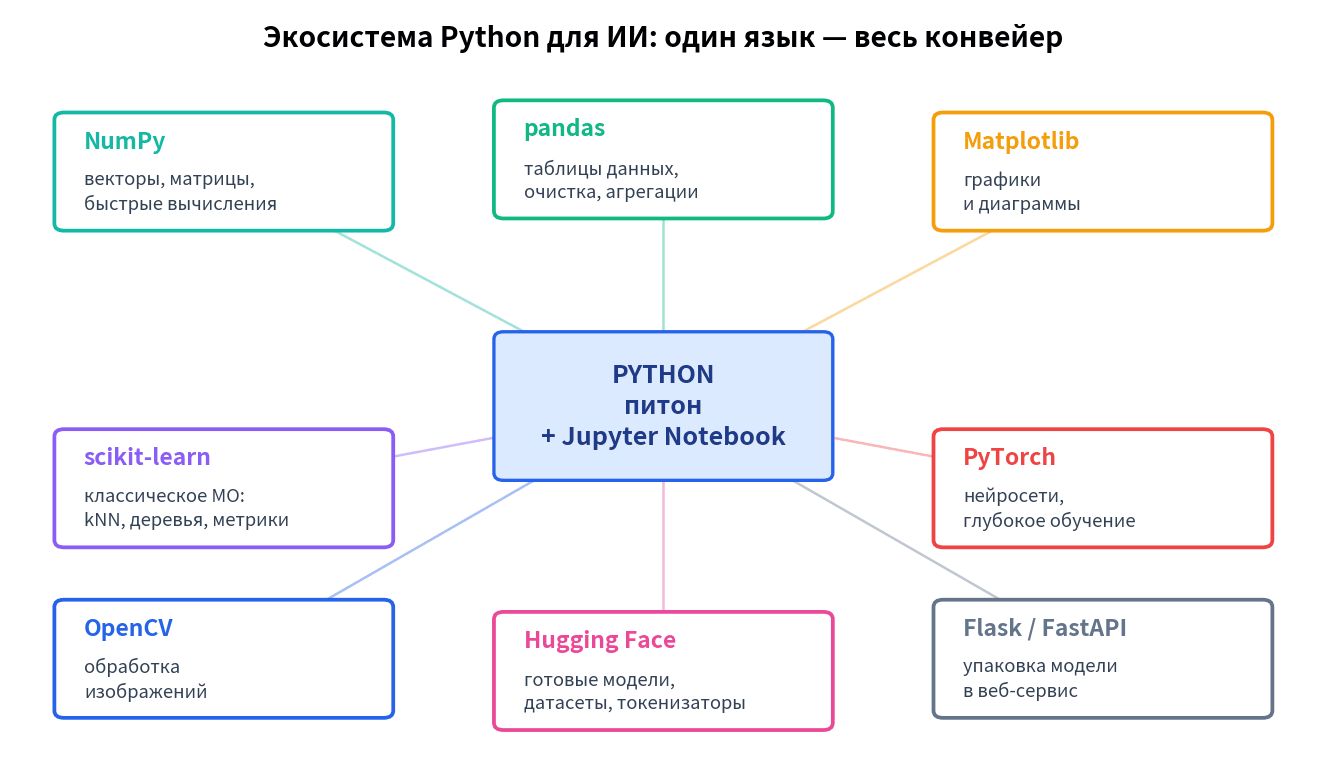

В течение курса мы пройдём этот стек по кругу: NumPy и pandas (практика 1–2), scikit-learn (практика 3–4), PyTorch (практика 5–6), OpenCV (практика 7), Hugging Face и Flask (практика 8–9). К концу все плитки мозаики будут в руках.

**Мини-шпаргалка по типам данных Python** (пригодится в коде):


### 🛠️ Из чего состоит рабочая среда

| Инструмент | Что это | Зачем нужен |
|---|---|---|
| **Python** | Язык программирования | На нём пишут модели ИИ |
| **Библиотека** | Набор готовых функций | Не писать всё с нуля (NumPy, Pandas) |
| **Anaconda** | Набор готовых библиотек + менеджер | Установка одной командой |
| **Jupyter Notebook** | «Тетрадь» с ячейками кода | Удобно для экспериментов и отчётов |
| **PyCharm** | Редактор для больших программ | Для серьёзных проектов |

> 💡 **Как читать сообщение об ошибке:** смотрите на **последнюю строку** — там обычно причина.

## 6. Рабочая среда: Anaconda, Jupyter и порядок ячеек

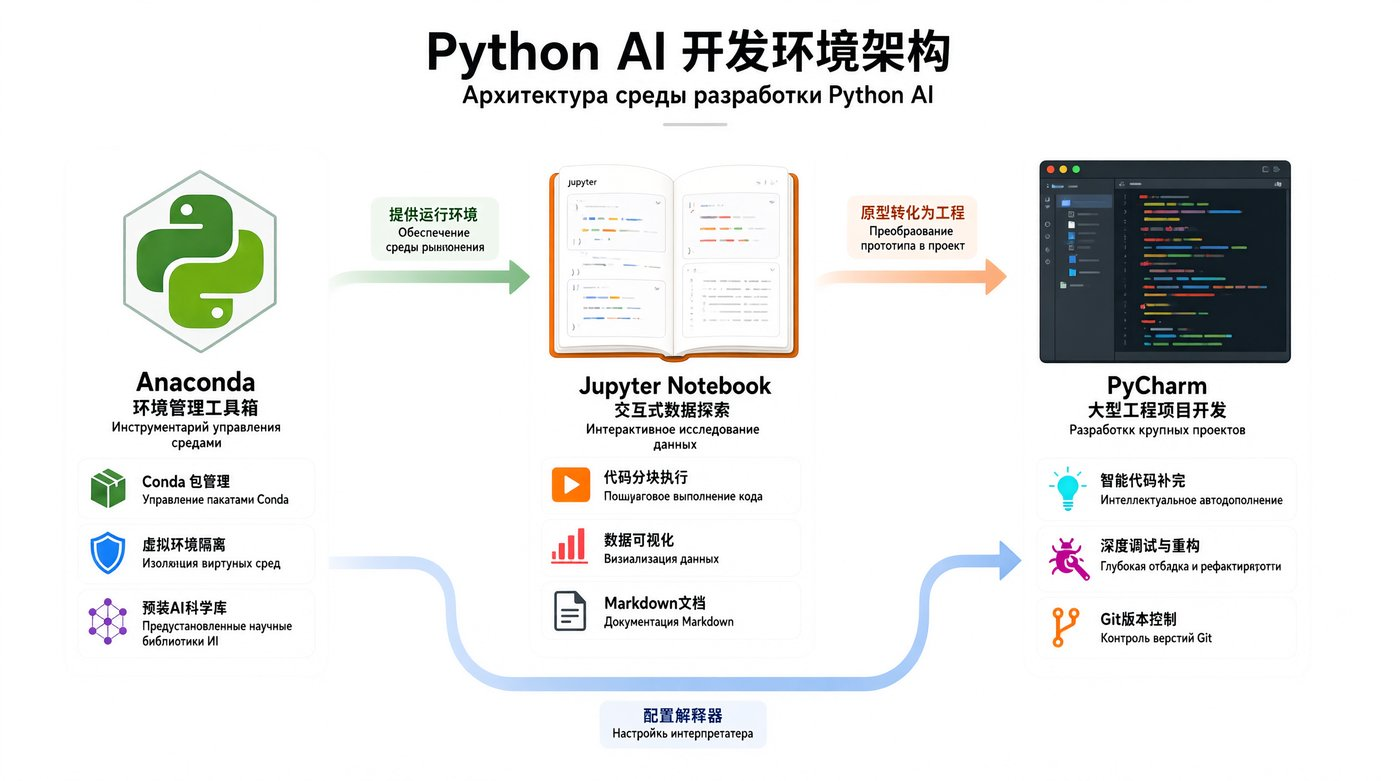

### 6.1. Кто чем управляет

## 📌 Что такое Anaconda?

**Anaconda** — это готовый набор всего нужного:
- Python
- 250+ библиотек (NumPy, Pandas, Matplotlib и др.)
- Менеджер пакетов conda
- Jupyter Notebook

Вместо того чтобы устанавливать каждую библиотеку отдельно, вы ставите Anaconda — и всё уже готово!

<div style='background-color: #E8F5E9; padding: 15px; border-left: 5px solid #388E3C; margin: 20px 0;'>
<b>💡 Аналогия:</b> Anaconda — это как «набор юного химика». Вместо того чтобы покупать каждую пробирку отдельно, вы покупаете готовый набор, где уже есть всё нужное.
</div>

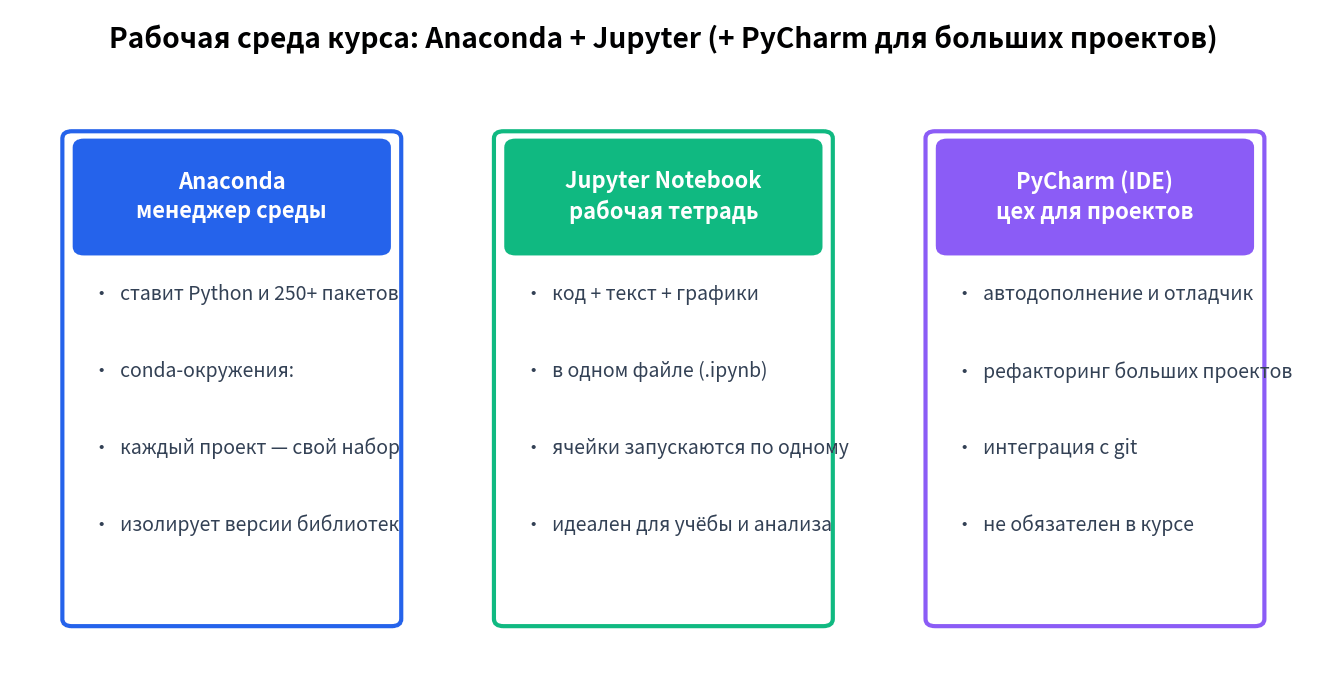

**Anaconda** ставит Python вместе с 250+ научными пакетами разом и даёт `conda` — менеджер окружений. Окружение (虚拟环境) — это «песочница» со своим набором библиотек: проект курса живёт в одном окружении, эксперимент — в другом, и они не конфликтуют. Команды, которые понадобятся:

```bash
conda create -n ai python=3.10 -y   # создать окружение ai
conda activate ai                   # войти в него
conda install numpy pandas scikit-learn matplotlib -y
jupyter notebook                    # запустить тетрадь
```

### 6.2. Ноутбук Jupyter и его главное правило


## 📓 Jupyter Notebook vs PyCharm

| Критерий | Jupyter Notebook | PyCharm |
|----------|------------------|--------|
| **Формат** | Тетрадь с ячейками код + текст + картинки | Полноценный редактор |
| **Запуск** | По одной ячейке | Вся программа сразу |
| **Удобно для** | Экспериментов, обучения, визуализации | Больших проектов, продакшена |
| **Результат** | Видно сразу после ячейки | Нужно запускать весь файл |
| **Файл** | `.ipynb` | `.py` |
| **В нашем курсе** | ✅ **Используем постоянно** | Упомянем для справки |


### Почему Jupyter удобен для обучения?

1. Можно запускать код по частям (по ячейкам)
2. Сразу видно результат
3. Можно писать текст (Markdown) рядом с кодом
4. Графики отображаются прямо в тетради
5. Легко делиться тетрадью с преподавателем


### 🌐 Работа в условиях ограничений интернета в КНР

Многие зарубежные сайты недоступны или работают нестабильно. Ниже — замены, которые заложены во все материалы.

| Что обычно используют | Проблема | Чем заменить |
|---|---|---|
| pip / PyPI | медленно, обрывы | зеркало Цинхуа https://pypi.tuna.tsinghua.edu.cn/simple |
| Anaconda / conda | медленно | установщики и каналы на mirrors.tuna.tsinghua.edu.cn/anaconda |
| Google Colab, Kaggle | недоступны | локальный Jupyter; онлайн — 百度飞桨 AI Studio, 天池 |
| GitHub, Hugging Face | нестабильно | Gitee (gitee.com), 魔搭 ModelScope (modelscope.cn) |
| ChatGPT, Gemini, Claude | недоступны | DeepSeek, 通义千问 (Qwen), Kimi, 豆包, 文心一言 |
| YouTube, Coursera | недоступны | Bilibili (B站), 中国大学MOOC, 学堂在线 |

В Китае есть и свои фреймворки глубокого обучения: **PaddlePaddle (飞桨, Baidu)** и **MindSpore (昇思, Huawei)**. О них стоит упомянуть на лекции 6.

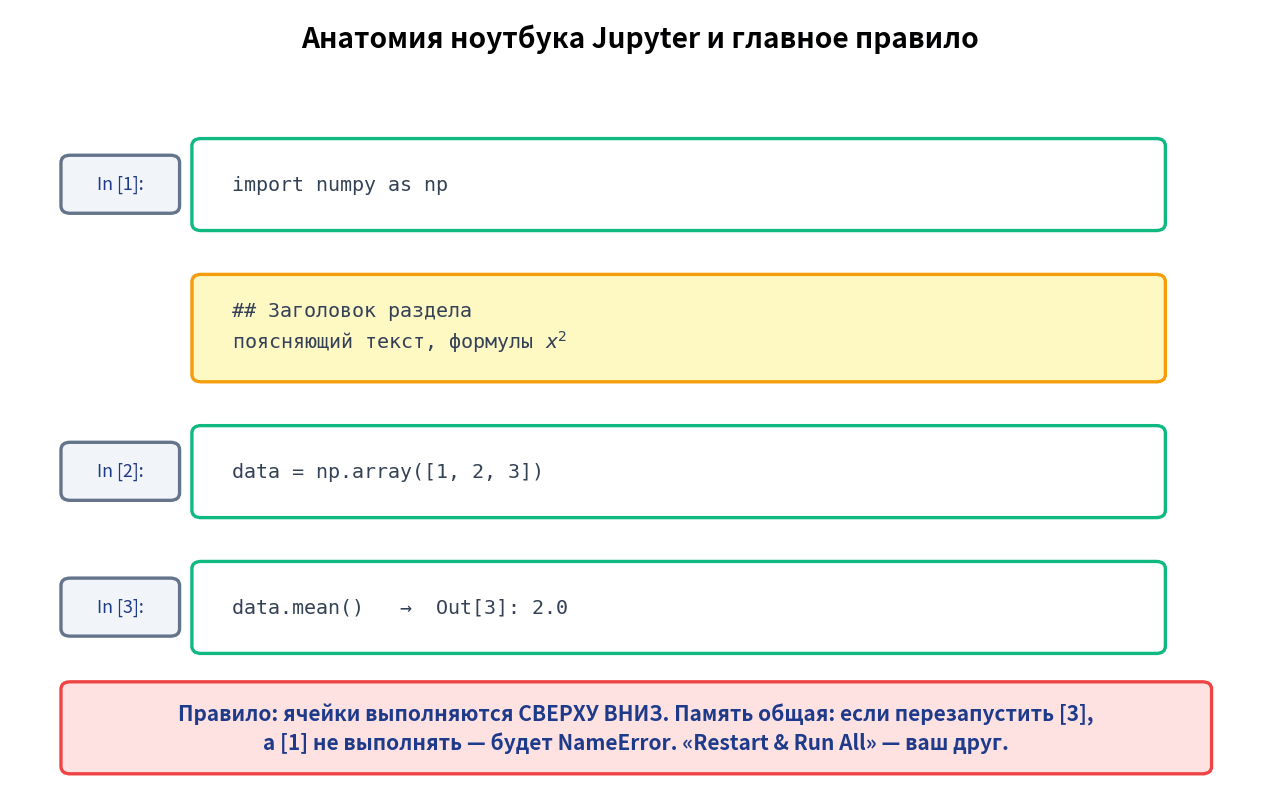

Ноутбук (.ipynb) — это JSON-файл с ячейками двух типов: **markdown** (текст, формулы, картинки — как этот) и **code** (исполняемый Python с результатом под ячейкой). Все лекции курса — именно такие ноутбуки.

Три кнопки, которые решают 90% проблем: `Restart` (стереть память ядра), `Run All` (выполнить всё), `Restart & Run All` (то и другое — «пересобрать с нуля»). **Правило:** ячейки выполняются сверху вниз; если «переменная не определена» — вы запустили ячейку раньше её определения.

### 6.3. Два практических правила курса

**Правило латиницы.** Пути и имена файлов — только латиницей: `lectures/images/fig1.png`, а не `Лекции/рисунки/рис1.png`. OpenCV и часть библиотек не читают кириллицу и иероглифы в путях — сэкономите себе часы отладки.

**Установка пакетов при ограниченном интернете.** В КНР стандартная практика — зеркала университетов (зеркало Tsinghua TUNA и аналоги): `pip install -i https://pypi.tuna.tsinghua.edu.cn/simple pandas`. Conda тоже умеет `--channel` с зеркалами. В кампусной сети зеркала обычно работают на полной скорости.


## 🔍 Как читать сообщение об ошибке

Ошибки — это нормально. Даже опытные программисты видят их каждый день. Главное — уметь их читать.

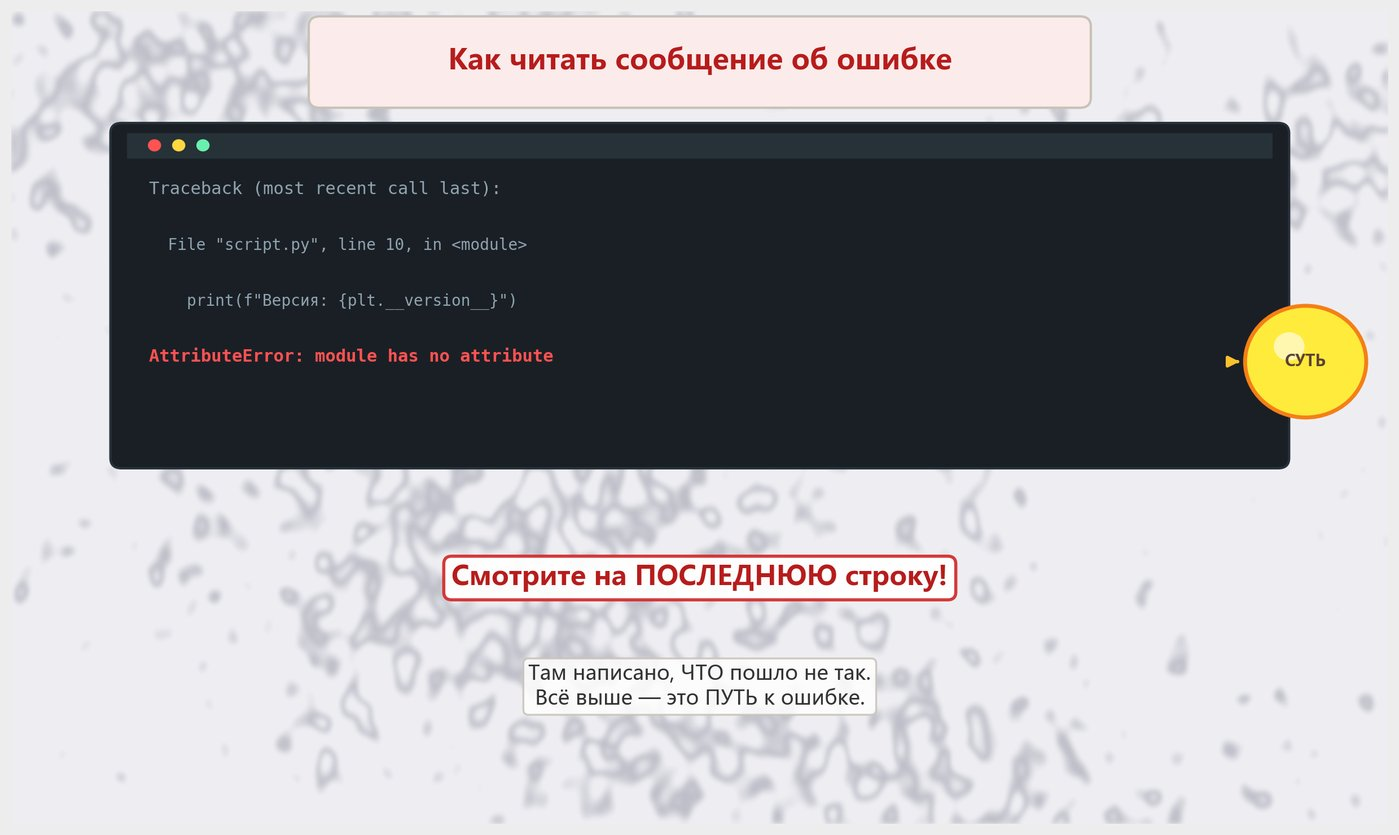

### Пример ошибки

```python
import matplotlib.pyplot as plt
print(plt.__version__)  # ← Ошибка!
```

**Сообщение об ошибке:**
```
Traceback (most recent call last):
  File "script.py", line 10, in <module>
    print(plt.__version__)
AttributeError: module 'matplotlib.pyplot' has no attribute '__version__'
```

### Как читать (по шагам):

1. **Смотрите на ПОСЛЕДНЮЮ строку** — там суть ошибки
2. `AttributeError` — у объекта нет такого атрибута
3. `module 'matplotlib.pyplot' has no attribute '__version__'` — у `pyplot` нет `__version__`
4. **Решение:** нужно импортировать `matplotlib` (главный модуль), а не только `pyplot`

### Правильный код:

```python
import matplotlib
print(matplotlib.__version__)  # Работает!
```

<div style='background-color: #FFEB3B; padding: 15px; border-left: 5px solid #F57F17; margin: 20px 0;'>
<b>💡 Правило:</b> Всё выше последней строки — это ПУТЬ к ошибке. Последняя строка — ЧТО пошло не так. Всегда читайте последнюю строку первой!
</div>

In [ ]:
# Проверка, что среда готова (этот код запустим на практике 1)
import sys
print('Версия Python:', sys.version)
print()

try:
    import numpy
    print('✅ NumPy', numpy.__version__)
except ImportError:
    print('❌ NumPy не установлен')

try:
    import pandas
    print('✅ Pandas', pandas.__version__)
except ImportError:
    print('❌ Pandas не установлен')

try:
    import sklearn
    print('✅ scikit-learn', sklearn.__version__)
except ImportError:
    print('❌ scikit-learn не установлен')

try:
    import matplotlib
    print('✅ Matplotlib', matplotlib.__version__)
except ImportError:
    print('❌ Matplotlib не установлен')

print()
print('Если все ✅ — среда готова к работе! 🎉')

Версия Python: 3.10.22 | packaged by Anaconda, Inc. | (main, Oct  1 2026, 20:15:38) [MSC v.1942 64 bit (AMD64)]

✅ NumPy 2.2.5
✅ Pandas 2.3.3
✅ scikit-learn 1.7.1
✅ Matplotlib 3.10.9

Если все ✅ — среда готова к работе! 🎉


### 🔧 Настройка зеркал для Китая

**Для pip:**
```bash
pip config set global.index-url https://pypi.tuna.tsinghua.edu.cn/simple
```

**Для conda** (файл `.condarc` в папке пользователя):
```yaml
channels:
  - defaults
show_channel_urls: true
default_channels:
  - https://mirrors.tuna.tsinghua.edu.cn/anaconda/pkgs/main
  - https://mirrors.tuna.tsinghua.edu.cn/anaconda/pkgs/r
custom_channels:
  conda-forge: https://mirrors.tuna.tsinghua.edu.cn/anaconda/cloud
  pytorch: https://mirrors.tuna.tsinghua.edu.cn/anaconda/cloud
```

---
## 🎬 Все видеоматериалы лекции 2
### 🇷🇺 РУС · русскоязычные видео
🎬 Практика: инструменты и библиотеки (16)
| № | Видео | Источник | Длит. | Раздел лекции | Доступность |
|---|-------|----------|-------|----------------|---|
| 1 | [ML для начинающих — первые шаги с Jupyter Notebook // Демо-занятие курса «Machine Learning. Basic»](https://vkvideo.ru/video-145052891_456249829) | VK · OTUS | 1:23:03 | П1 Шаг 5: запуск и работа в Jupyter Notebook · [добавлено] | X |
| 2 | [#1. Пакет numpy — установка и первое знакомство \| NumPy уроки](https://rutube.ru/video/6a4b926d1bff5361164e78fdd0af0e2b/) | Rutube · SelfEdu | 11:42 | П2: знакомство с NumPy · [добавлено] | X |
| 3 | [#2. Основные типы данных, создание массивов \| NumPy уроки](https://rutube.ru/video/348f5d770378aa528bfcbf35a1bbea60) | Rutube · SelfEdu | 13 мин | П2: массивы NumPy | X |
| 4 | [#3. Функции автозаполнения, создания матриц и числовых диапазонов \| NumPy уроки](https://rutube.ru/video/adca14c9c9c62782e6dc869cd1961693/) | Rutube · SelfEdu | 21:23 | П2: создание массивов (zeros, ones, arange) · [добавлено] | X |
| 5 | [#4. Свойства и представления массивов, создание их копий \| NumPy уроки](https://rutube.ru/video/14805e57d82eb9d96bae3d6b3e721926/) | Rutube · SelfEdu | 12:06 | П2: dtype, shape, view и copy · [добавлено] | X |
| 6 | [#5. Изменение формы массивов, добавление и удаление осей \| NumPy уроки](https://rutube.ru/video/e13036a10750f0a8680a8d95c0598dc8/) | Rutube · SelfEdu | 16:38 | П2: reshape, transpose, newaxis · [добавлено] | X |
| 7 | [#6. Объединение и разделение массивов \| NumPy уроки](https://rutube.ru/video/674030b91559fa6c27af9fd4b61dceb2/) | Rutube · SelfEdu | 14:18 | П2: hstack, vstack, split · [добавлено] | X |
| 8 | [#7. Индексация, срезы, итерирование массивов \| NumPy уроки](https://rutube.ru/video/85205eebadfeb32808a2b4d9edf188ae/) | Rutube · SelfEdu | 27:59 | П2: индексация и срезы · [добавлено] | X |
| 9 | [#8. Базовые математические операции над массивами \| NumPy уроки](https://rutube.ru/video/6d9f92f2ee23ccad960b39710142e925/) | Rutube · SelfEdu | 10:49 | П2: поэлементные операции · [добавлено] | X |
| 10 | [#9. Булевы операции и функции, значения inf и nan \| NumPy уроки](https://rutube.ru/video/a8390836b9fd198175a8115e9a1ae33b/) | Rutube · SelfEdu | 12:31 | П2: булева индексация, NaN · [добавлено] | X |
| 11 | [#10. Базовые математические функции \| NumPy уроки](https://rutube.ru/video/3b37fe8a88e2f3e62591c291b5700310/) | Rutube · SelfEdu | 17:48 | П2: агрегаты, random, статистика · [добавлено] | X |
| 12 | [#11. Произведение матриц и векторов \| NumPy уроки](https://rutube.ru/video/d2338650063b2e929003832eacf12ad4) | Rutube · SelfEdu | 13 мин | Л2 §3 / П2: матричные операции в коде | X |
| 13 | [#12. Множества (unique) и операции над ними \| NumPy уроки](https://rutube.ru/video/2bea9a3892784eaa66de6740b585ecce/) | Rutube · SelfEdu | 08:35 | П2: unique, пересечения и объединения · [добавлено] | X |
| 14 | [#13. Транслирование массивов \| NumPy уроки](https://rutube.ru/video/179b90140770fb0a0365e35d6240c010/) | Rutube · SelfEdu | 10:35 | П2: broadcasting · [добавлено] | X |
| 15 | [Практика Pandas: NaN, Null — теория заполнения пропусков](https://rutube.ru/video/8621871d14e50231d0f20498fb566f99/) | Rutube · SALDA.WS | 14:13 | [новая] П2: работа с пропусками в таблицах | ✓ |
| 16 | [✅ 1. Знакомство с Pandas. Типы данных \| Курс по Pandas](https://rutube.ru/video/05eba9f39fed2db13eebbd0efbee419f/) | Rutube · Сергей Дубинин | 13:55 | П2: знакомство с Pandas · [добавлено] | X |


### 🇨🇳 中文 · китайскоязычные видео (7)
| № | Видео | Источник | Длит. | Раздел лекции | Доступность |
|---|-------|----------|-------|----------------|-------------|
| 1 | [Python-анализ данных: NumPy, Pandas, Matplotlib](https://www.bilibili.com/video/BV1hx411d7jb)<br>· ориг.: *Python数据分析 NumPy Pandas Matplotlib* | Bilibili · luvm的小屋 | курс (42 сер.) | [новая] Л2 · П2: три главные библиотеки курса | ✓ |
| 2 | [Буткемп аналитика данных на Python (84 урока)](https://www.bilibili.com/video/BV1HJ411j7NG)<br>· ориг.: *Python数据分析训练营 84课* | Bilibili | курс (84 ур.) | [новая] Л2 · П2: расширенная практика анализа данных | ✓ |
| 3 | [Установка PyCharm и Anaconda](https://www.bilibili.com/video/BV1DgxCzREbM?p=8)<br>· ориг.: *【入门篇】pycharm和anaconda的安装* | Bilibili (анимакурс) | 22 мин | П1: рабочая среда · [перенесено из Л2 §6] | ✓ |
| 4 | [Настройка окружения и практика синтаксиса Python](https://www.bilibili.com/video/BV1ctQzYUEbz?p=4)<br>· ориг.: *3.环境配置及Python语法实操* | Bilibili · 清华36 | 22 мин | Л2 §5–6 / П1: среда и язык | ✓ |
| 5 | [Обзор сред и инструментальных пакетов](https://www.bilibili.com/video/BV1ug4y1t7Ty?p=4)<br>· ориг.: *1-4 环境及工具包介绍* | Bilibili · 清华AI | 17 мин | Л2 §6 / П1: инструментарий | ✓ |
| 6 | [Практика: Pandas, NumPy, Matplotlib](https://www.bilibili.com/video/BV1ctQzYUEbz?p=5)<br>· ориг.: *4. Pandas、Numpy、Matplotlib实操* | Bilibili · 清华36 | 23 мин | П2: три главные библиотеки в работе | ✓ |
| 7 | [Предобработка данных: реализация](https://www.bilibili.com/video/BV1EY6FBwE8P?p=8)<br>· ориг.: *8.3-数据预处理实现* | Bilibili · 李沐 | 7 мин | Л2 §1–2 / П2: пропуски, типы | ✓ |



---
## ❓ Мини-тест

### Проверьте себя

Ответьте устно или письменно:

1. **Что такое вектор в вашем примере?**
   <details>
   <summary>Показать ответ</summary>
   Вектор — это список чисел, описывающих один объект. Например, оценки одного студента по пяти предметам: [78, 92, 65, 88, 71]. Или параметры квартиры: [45, 2, 5, 7.5].
   </details>

2. **Как вычислить среднее по пяти оценкам?**
   <details>
   <summary>Показать ответ</summary>
   Сложить все оценки и разделить на их количество. Например: (78+92+65+88+71) / 5 = 394 / 5 = 78.8
   </details>

3. **Чем Jupyter отличается от PyCharm?**
   <details>
   <summary>Показать ответ</summary>
   Jupyter — это тетрадь с ячейками кода, удобно для экспериментов и обучения. PyCharm — полноценный редактор для больших проектов. В нашем курсе мы используем Jupyter.
   </details>

4. **Что делать, если появилась ошибка `AttributeError`?**
   <details>
   <summary>Показать ответ</summary>
   Смотреть на последнюю строку ошибки. Там написано, у какого объекта нет какого атрибута. Проверить, правильно ли написано имя, импортирован ли модуль. Возможно, нужно импортировать родительский модуль.
   </details>

5. **Приведите пример вектора из вашей жизни.**
   <details>
   <summary>Показать ответ</summary>
   Например: мои расходы за месяц [еда: 2000, транспорт: 500, развлечения: 800, учёба: 300]. Или: мои оценки за семестр [математика: 85, физика: 78, английский: 92].
   </details>

### Контрольные вопросы

Нажмите на вопрос, чтобы раскрыть образец ответа.

**1. Сколько данных примерно нужно, чтобы: (а) отличить два сорта цветов, (б) распознавать кошек и собак на любых фото, (в) обучить большую языковую модель? Почему ответ зависит от задачи?**
<details>
<summary>Показать ответ</summary>
(а) Сотни примеров (ирисы Фишера — 150); (б) десятки–сотни тысяч фото — вариаций света, ракурсов и пород много; (в) триллионы токенов текста. Чем сложнее и вариативнее закономерность, тем больше данных нужно: модели нужно «увидеть» все варианты мира задачи.
</details>

**2. Почему сравнение чайника и термопота «в лоб» даёт бессмысленный результат и как это исправить?**
<details>
<summary>Показать ответ</summary>
Признаки в разных единицах и масштабах: цена (сотни юаней) перекрикивает объём (единицы литров), и расстояние определяется самым «крупным» признаком. Исправление — <b>нормализация</b>: привести все признаки к одной шкале (деление на максимум столбца или стандартизация `StandardScaler`). После этого расстояние становится осмысленной мерой непохожести.
</details>

**3. Объясните принцип «мусор на входе — мусор на выходе». К чему он приводит на практике?**
<details>
<summary>Показать ответ</summary>
Модель честно воспроизводит качество данных: пропуски, выбросы и разный масштаб превращаются в ерундовые предсказания — 垃圾进，垃圾出. Практический вывод: <b>сбор и очистка данных занимают 60–80% времени проекта</b>, и начинать их надо с первого дня, а не за неделю до сдачи.
</details>

**4. Перечислите основные библиотеки курса (NumPy, Pandas, Matplotlib, scikit-learn, PyTorch, OpenCV) и назначение каждой.**
<details>
<summary>Показать ответ</summary>
<b>NumPy</b> — векторы, матрицы, быстрая математика; <b>Pandas</b> — таблицы и очистка данных; <b>Matplotlib</b> — графики; <b>scikit-learn</b> — классические алгоритмы МО (kNN, деревья, k-means); <b>PyTorch</b> — нейросети и глубокое обучение; <b>OpenCV</b> — обработка изображений и компьютерное зрение.
</details>

**5. Почему фото 12 Мп — это 36 миллионов чисел? Из чего они состоят?**
<details>
<summary>Показать ответ</summary>
12 миллионов пикселей × <b>3 канала (R, G, B)</b> = 36 млн чисел. Каждое число — яркость одного из трёх базовых цветов в одной точке. Для компьютера фото — трёхмерный тензор «высота × ширина × каналы» (лекция 6).
</details>

**6. Зарплатный ряд: [20, 20, 20, 20, 500]. Посчитайте среднее и медиану и объясните разницу.**
<details>
<summary>Показать ответ</summary>
Среднее = (20·4 + 500)/5 = <b>116</b>; медиана = <b>20</b> (середина отсортированного ряда). Среднее «съел» выброс 500, медиана почти не шевельнулась. «Типичная» зарплата описывается медианой — это то же правило, что для MAE/RMSE в лекции 4.
</details>

**7. Из 500 писем 50 спам, в 40 из них слово «акция»; в 10 не-спаме тоже. Оцените P(спам|«акция») по Байесу.**
<details>
<summary>Показать ответ</summary>
Из 50 писем со словом «акция» 40 — спам: P(спам | «акция») = 40/50 = <b>0,8</b>. Байес «перевернул» условие: была статистика «насколько часто слово встречается в спаме», стал ответ «насколько письмо с словом — спам». Так работал первый спам-фильтр 1990-х.
</details>

**8. Приведите свой пример ложной корреляции и «третьей переменной».**
<details>
<summary>Показать ответ</summary>
Классика: продажи мороженого коррелируют с числом утоплений — третья переменная <b>жаркая погода</b> (летом и больше мороженого, и больше купаний). Мораль: корреляция ≠ причинность; сначала ищите третью переменную.
</details>

**9. Чем conda-окружение отличается от папки проекта? Зачем изоляция?**
<details>
<summary>Показать ответ</summary>
Окружение (虚拟环境) — «песочница» со своей версией Python и своим набором библиотек; папка проекта — только его файлы. Изоляция защищает проекты от конфликтов версий: одному нужен scikit-learn 1.3, другому — 0.24. Команды: `conda create -n ai`, `conda activate ai`.
</details>

**10. Почему в ноутбуке нельзя исполнять ячейки в случайном порядке?**
<details>
<summary>Показать ответ</summary>
Все ячейки делят <b>общую память ядра</b>: переменная должна быть определена до использования. Случайный порядок даёт `NameError` и невоспроизводимые результаты. Правило: сверху вниз; если запутались — `Restart & Run All` («пересобрать с нуля»).
</details>


---
## 🏠 Домашнее задание

### Задание 1: Практика в Jupyter (15 минут)

Откройте Jupyter Notebook и выполните:

1. Создайте вектор из 5 любых чисел (например, ваши оценки)
2. Найдите среднее, максимум, минимум, стандартное отклонение
3. Создайте матрицу 3×2 (3 строки, 2 столбца)
4. Умножьте матрицу на вектор весов [0.4, 0.6]

**Шаблон кода:**
```python
import numpy as np

# 1. Вектор из 5 чисел
vector = np.array([10, 20, 30, 40, 50])
print('Среднее:', vector.mean())
print('Максимум:', vector.max())
print('Минимум:', vector.min())
print('Стандартное отклонение:', vector.std())

# 2. Матрица 3x2
matrix = np.array([[1, 2], [3, 4], [5, 6]])
print('\nМатрица:')
print(matrix)

# 3. Вектор весов
weights = np.array([0.4, 0.6])

# 4. Умножение
result = matrix @ weights
print('\nРезультат умножения:', result)
```

### Задание 2: Анализ ошибки (10 минут)

Найдите и исправьте ошибку в коде:

```python
import matplotlib.pyplot as plt
x = [1, 2, 3]
y = [4, 5, 6]
plt.plt(x, y)  # ← Что не так?
plt.show()
```

**Подсказка:** Посмотрите на последнюю строку ошибки. Что означает `AttributeError`?

### Задание 3: Подумайте и напишите (10 минут)

Приведите пример из жизни, где используется:
- **Вектор** (список чисел)
- **Матрица** (таблица чисел)
- **Вероятность** (оценка шансов)

**Пример:**
> **Вектор:** мои расходы за месяц [еда: 2000, транспорт: 500, развлечения: 800]
> **Матрица:** расходы всех студентов группы за месяц (каждый студент — строка)
> **Вероятность:** шанс дождя завтра 30% (по прогнозу погоды)

### Задание 4 (по желанию): Исследование (10 минут)

Попробуйте в Jupyter:
```python
import numpy as np

# Создайте два вектора с одинаковым средним, но разным разбросом
v1 = np.array([7, 7, 7, 7, 7])  # все одинаковые
v2 = np.array([2, 12, 3, 11, 7])  # сильно различаются

print('v1 среднее:', v1.mean(), 'разброс:', v1.std())
print('v2 среднее:', v2.mean(), 'разброс:', v2.std())
```

Что вы заметили? Почему разброс разный, хотя среднее одинаковое?

<div style='background-color: #E8F5E9; padding: 15px; border-left: 5px solid #388E3C; margin: 20px 0;'>
<b>💡 Совет:</b> Если что-то непонятно — перечитайте раздел с примерами. Математика в ИИ — это не страшно, это просто инструменты! Главное — понять идеи, а не зубрить формулы.
</div>

## 📚 Глоссарий Лекции 2 (词汇表)

Термины данных, математики и экосистемы Python (общие термины ИИ — в Лекции 1).

| Термин (рус) | English | 中文 | Пояснение |
|--------------|---------|------|-----------|
| Данные | Data | 数据 | Материал для ML; качество данных важнее хитрости алгоритма. |
| Вектор | Vector | 向量 | Упорядоченный набор чисел; представляет объект или признак. |
| Матрица | Matrix | 矩阵 | Прямоугольная таблица чисел; в ML — набор векторов-строк. |
| Тензор | Tensor | 张量 | Многомерный массив; обобщение вектора и матрицы. |
| Скалярное произведение | Dot product | 点积 | Сумма попарных произведений компонент; мера сонаправленности векторов. |
| Косинусное сходство | Cosine similarity | 余弦相似度 | Похожесть векторов по углу; нечувствительно к длине. |
| Расстояние | Distance | 距离 | Числовая мера различия объектов; близко = похоже. |
| Евклидово расстояние | Euclidean distance | 欧氏距离 | «Прямая» дистанция между точками в пространстве признаков. |
| Среднее | Mean | 均值 | Сумма значений, делённая на их количество; центр распределения. |
| Медиана | Median | 中位数 | Середина упорядоченного ряда; устойчива к выбросам. |
| Стандартное отклонение | Standard deviation | 标准差 | Мера разброса значений вокруг среднего. |
| Дисперсия | Variance | 方差 | Квадрат стандартного отклонения; мера разброса. |
| Гистограмма | Histogram | 直方图 | Столбчатый график распределения частот значений. |
| Вероятность | Probability | 概率 | Число от 0 до 1, выражающее уверенность в событии. |
| Теорема Байеса | Bayes' theorem | 贝叶斯定理 | Правило переворота условной вероятности; основа наивного Байеса. |
| Корреляция | Correlation | 相关性 | Статистическая связь двух переменных; ≠ причинность. |
| Причинность | Causation | 因果关系 | Связь «причина → следствие»; не эквивалентна корреляции. |
| NumPy | NumPy | NumPy | Библиотека векторных вычислений Python; основа всех численных библиотек. |
| Pandas | Pandas | Pandas | Библиотека таблиц DataFrame; аналог SQL в Python. |
| Anaconda | Anaconda | Anaconda | Дистрибутив Python + научные пакеты + менеджер conda. |


## 🎓 Итоги Лекции 2

Лекция заложила математический и инструментальный фундамент курса: данные — топливо ИИ, любая информация превращается в числа, векторы и матрицы — рабочий язык моделей, расстояние — мера похожести, Байес и статистика — основа принятия решений.

### 🔑 Главные выводы

1. Данные — топливо ИИ: их количество, разнообразие и чистота важнее хитрости алгоритма.
2. Любая информация — фото, текст, звук — превращается в числа (векторизация).
3. Три кита: вектор (объект), матрица (таблица и преобразование), расстояние (похожесть). $X\mathbf{w}$ — прогноз для всей таблицы сразу.
4. Косинусное сходство — «похожесть вкусов»; нормировка признаков обязательна перед расстояниями.
5. Среднее/медиана/σ описывают распределение; Байес переворачивает условную вероятность — так работал первый спам-фильтр.
6. Корреляция не доказывает причинность и ловит только линейную связь.
7. Стек курса: Python → NumPy/pandas → scikit-learn → PyTorch (+ OpenCV, Hugging Face, Flask). Среда: Anaconda + Jupyter; ячейки — сверху вниз.

### 📅 Следующее занятие

**Лекция 3: Как машина учится — понятия и типы машинного обучения**

**Практика 2: Работа с данными — очистка, пропуски, выбросы, преобразования**

---

<center><i>Преподаватель: _______________</i></center>
<center><i>Дата проведения: _______________</i></center>